# Entregable 1: segmentación de instancias de tornillos en WDSD

**Autores:** Ivan Berrio, Jose David Castillo y Jaime Besada.

## 1. Introducción

### Problema

En el desmontaje automatizado de residuos de aparatos eléctricos y electrónicos (*Waste Electrical and Electronic Equipment*, WEEE), un robot necesita localizar los tornillos antes de retirarlos. En este proyecto, el problema se aborda mediante **segmentación de instancias**. Para cada imagen, el modelo genera una máscara por tornillo, que permite identificar su ubicación y su forma visible. Se desea comparar el desempeño de tres modelos de segmentación de instancias en imágenes del dataset WDSD y establecer una línea base que sirva de referencia para evaluar modelos más avanzados.

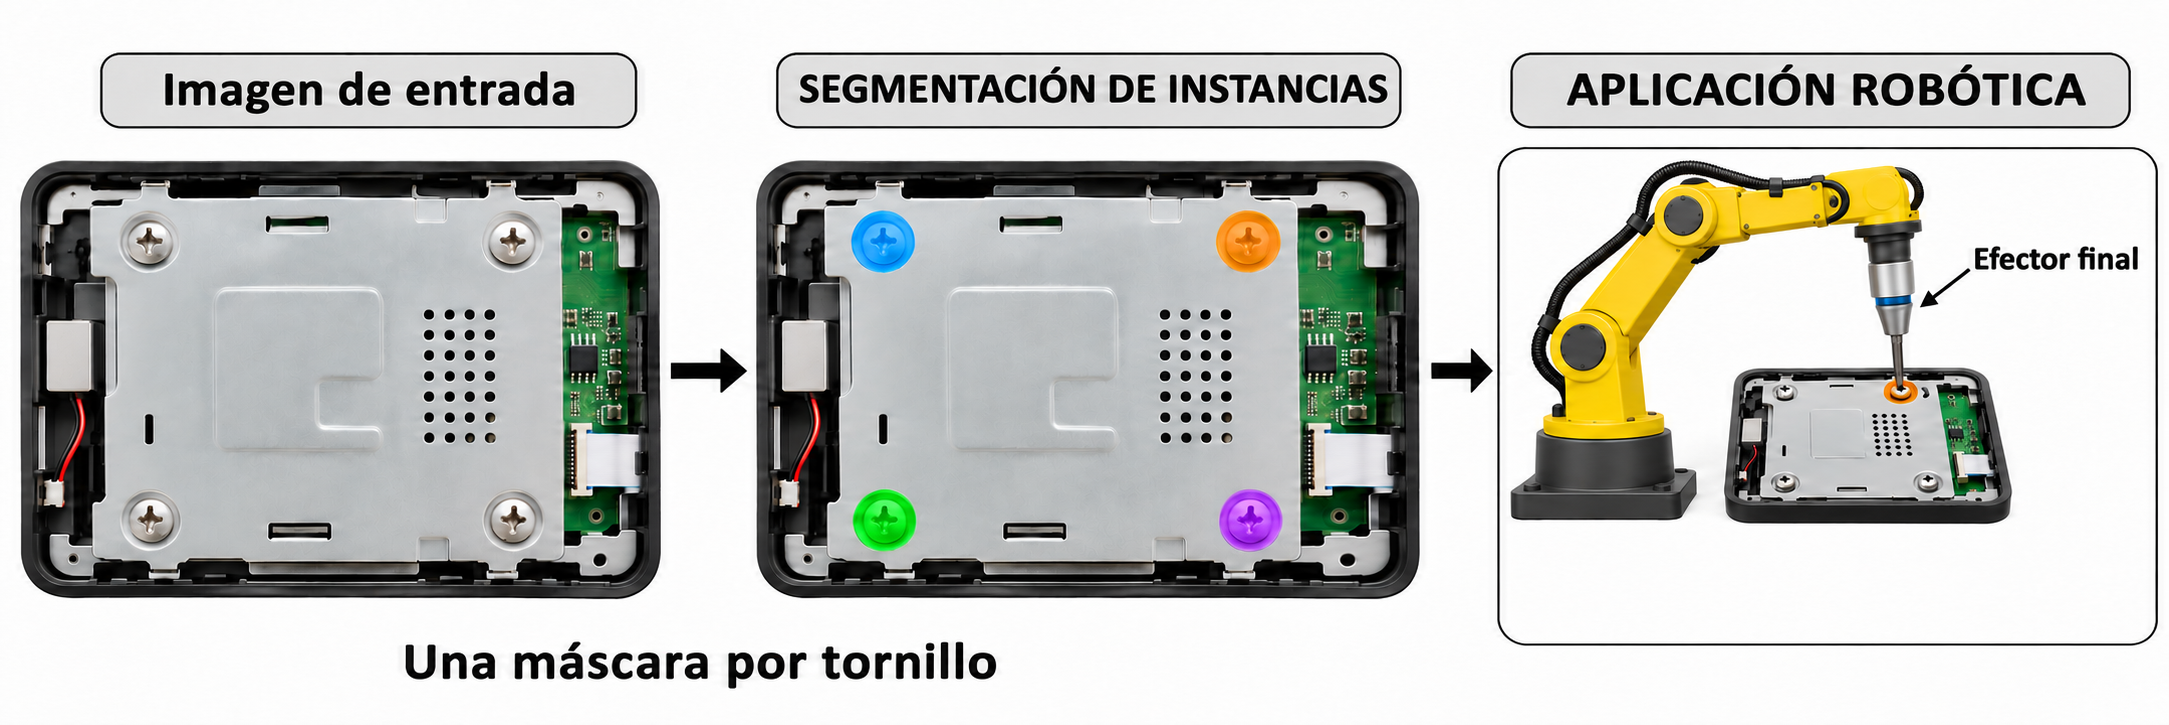

*Figura 1. Esquema conceptual de la segmentación de instancias de tornillos y su posible aplicación robótica.*

### Datos

WEEE Disassembly Screw Dataset (WDSD; Kalitsios et al., 2022, ICRCV, 10.1109/ICRCV55858.2022.9953178): 945 imágenes de 1280×720 con anotaciones COCO de tornillos. Usamos una partición agrupada por sesión de captura (744/93/108 imágenes; 14 grupos en prueba), porque la partición oficial tiene fuga por casi duplicados.

### Métrica primaria

F1 de instancia por imagen (emparejamiento húngaro, IoU de máscara ≥ 0.5), con δ = 0.03 como diferencia práctica mínima. Secundarias: PQ y AP50 de máscara.

**Estructura del informe.**
- **Sección 2.** EDA orientado a instancias.
- **Sección 3.** Revisión de literatura con PRISMA 2020 y tabla de síntesis.
- **Sección 4.** Implementación de los tres modelos base (Mask R-CNN, YOLOv8-seg y SOLOv2) con 5 semillas cada uno.
- **Sección 5.** Línea base estadística.
- **Sección 6.** Conclusiones.

El código, las dependencias (`requirements_*.txt`), la declaración a priori (`results/eda/declaracion_a_priori_instancias.json`) y los resultados de las 15 corridas están en el repositorio. Los análisis heredados del EDA general (inventario, casi duplicados, grupos de independencia y construcción de la partición) están en `notebooks/01_eda_wdsd.ipynb`.

## 2. EDA orientado a instancias


Entregable 1 de Deep Learning. Este notebook rehace el EDA de WDSD con cada tornillo como unidad de análisis. Responde al bloque G del enunciado (segmentación de imágenes) y al EDA general 2.1, ahora medidos por instancia.

Su relación con [`01_eda_wdsd.ipynb`](01_eda_wdsd.ipynb):

- **Lo que se hereda sin repetir:** inventario, huella SHA-256, casi duplicados por pHash, grupos de independencia, partición agrupada congelada, intensidad y normalización. Esos análisis no dependen de si la salida es semántica o de instancias.
- **Lo que cambia:** la verdad de referencia pasa a ser el polígono COCO de cada tornillo, la métrica primaria pasa a ser de instancia y la declaración a priori se sustituye por `results/eda/declaracion_a_priori_instancias.json`.

Como en el 01, cada análisis termina con la decisión de preprocesamiento, el impacto en la arquitectura y los riesgos. No se entrena ningún modelo.

> **Nota de integración.** Este EDA se escribió antes de la revisión de literatura, y por eso asume como modelos base las familias que el enunciado sugiere para segmentación (FCN, codificador-decodificador y U-Net reducida, con componentes conexas). La revisión de la sección 3 encontró que, en la literatura de segmentación de instancias de tornillos y sujetadores, los modelos de referencia son **Mask R-CNN, YOLOv8-seg y SOLOv2**, y esos son los que se implementan en la sección 4.
>
> Los hallazgos del EDA sobre los datos se mantienen: tamaño de los tornillos, ausencia de contacto entre ellos, umbral de IoU, partición y unidad de independencia. Lo que cambia son las implicaciones de arquitectura (entrada, pérdida y postproceso). Después de la tabla de la sección 2.12, una nota resume lo que finalmente se implementó. El enfoque semántico con componentes conexas queda como candidato para el benchmark del E2.

### 2.0 Configuración

In [ ]:
import sys, json, platform, warnings
from pathlib import Path
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from PIL import Image
from scipy import stats, ndimage as ndi
from skimage import measure
from skimage.segmentation import find_boundaries
from wdsd_e1 import eda as E, instancias as N

SEED = E.SEED
rng = np.random.default_rng(SEED)
COLOR = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
SPLITS = ['train', 'val', 'test']
TINTA, GRIS, ACENTO = '#0b0b0b', '#52514e', '#2a78d6'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .7, 'axes.axisbelow': True,
    'text.color': TINTA, 'axes.labelcolor': GRIS, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9.5, 'legend.frameon': False})
pd.set_option('display.width', 180, 'display.max_columns', 30)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

Python 3.9.25 | numpy 1.25.2 | pandas 2.1.0 | matplotlib 3.7.2


### 2.1 Definición del problema como segmentación de instancias

**Tipo de problema:** 8, segmentación de imágenes, en su variante de instancias. El enunciado no separa semántica e instancias, así que el tipo declarado no cambia; cambian la salida, la métrica y la unidad de error.

**Formulación.** La entrada es una imagen $x \in \mathcal{X} = [0,255]^{720 \times 1280 \times 3}$. La salida es un conjunto de máscaras disjuntas, una por tornillo, $y = \{M_1, \dots, M_K\}$ con $M_k \subset \Omega = \{1..720\} \times \{1..1280\}$ y $K$ variable. Se busca $f: \mathcal{X} \to \mathcal{Y}$ que acierte cuántos tornillos hay y dónde está cada uno. La pérdida que se minimiza depende del modelo; para los modelos base del enunciado (FCN, codificador-decodificador, U-Net reducida) es una pérdida por píxel, Dice más entropía cruzada, seguida de un etiquetado de componentes conexas que convierte la máscara en instancias. La sección 2.6 comprueba que ese paso es válido en este dataset.

**Pregunta de investigación.** ¿Cuál de los tres modelos base de la literatura localiza mejor cada tornillo en escenas de desmontaje de RAEE con escenas nunca vistas en el entrenamiento, y qué nivel debe superar un modelo avanzado?

**Hipótesis operativa.** Las diferencias de F1 de instancia por imagen entre los modelos base son mayores que el margen $\delta$ declarado en la sección 2.13.

**Unidad de independencia:** el grupo de escena del notebook 01 (186 grupos). La imagen es la unidad de medida de la métrica y el grupo es la unidad de remuestreo para la inferencia.

### 2.2 Estructura de las anotaciones de instancia

In [ ]:
df = E.inventario()
par = pd.read_csv(E.RESULTS / 'particion.csv')
dec01 = json.load(open(E.RESULTS / 'declaracion_a_priori.json', encoding='utf8'))
coco = E.carga_coco()
filas = []
for k in SPLITS:
    d = coco[k]
    a = d['annotations']
    filas.append({'split_oficial': k, 'imagenes': len(d['images']), 'instancias': len(a),
        'categorias': ', '.join(c['name'] for c in d['categories']),
        'ids_unicos': len({x['id'] for x in a}) == len(a),
        'iscrowd_1': sum(x['iscrowd'] for x in a),
        'con_2_poligonos': sum(len(x['segmentation']) > 1 for x in a),
        'imagenes_sin_instancia': len({i['id'] for i in d['images']} - {x['image_id'] for x in a})})
display(pd.DataFrame(filas).set_index('split_oficial'))
print('Huella del dataset igual a la del EDA 01:', E.huella_dataset(df) == dec01['sha256_dataset'])

ins, acu = N.tablas_instancias(df)
ins = ins.merge(par[['archivo', 'split', 'grupo', 'familia']], on='archivo', how='left')
ins['diametro'] = np.sqrt(4 * ins.area_coco / np.pi)
print('Instancias:', len(ins), '| sin partición asignada:', ins.split.isna().sum(),
      '| imágenes con instancias:', ins.archivo.nunique(), 'de', len(df))

,imagenes,instancias,categorias,ids_unicos,iscrowd_1,con_2_poligonos,imagenes_sin_instancia
split_oficial,,,,,,,
train,765,3578,Screw,True,0,2,0
val,90,402,Screw,True,0,0,0
test,90,418,Screw,True,0,0,0


Huella del dataset igual a la del EDA 01: True
Instancias: 4398 | sin partición asignada: 0 | imágenes con instancias: 945 de 945


Hay una sola categoría (`Screw`), ninguna anotación de grupo (`iscrowd = 0`) y todas las imágenes tienen al menos un tornillo. Solo 2 de 4.398 instancias están partidas en dos polígonos.

**Decisión de preprocesamiento.** Se usa una sola clase y se trata cada anotación como una instancia, uniendo los dos polígonos de las 2 instancias partidas.

**Impacto en la arquitectura.** Basta una salida binaria (tornillo o fondo) más la separación en instancias; no hace falta cabeza de clasificación multiclase.

**Riesgos.** Como no hay imágenes sin tornillos, el conjunto de prueba no mide falsos positivos en escenas vacías. Esto se declara como limitación de validez externa.

### 2.3 Calidad de las anotaciones de instancia

Se comprueban tres cosas: que el área declarada coincide con el polígono, que la caja coincide con el polígono y cuánto se parecen las dos versiones de la anotación (polígonos COCO y máscara PNG).

In [ ]:
print('Píxeles rasterizados por centros de píxel igual a area COCO:', (ins.px == ins.area_coco).mean())
desf = pd.DataFrame({'x0': ins.x - ins.px_x0, 'y0': ins.y - ins.px_y0,
                     'x1': ins.x + ins.w - ins.px_x1, 'y1': ins.y + ins.h - ins.px_y1})
print('Desfase caja - polígono (valor más frecuente por lado):', desf.round(1).mode().iloc[0].to_dict())
raras = ins.loc[(desf.round(1) != 0.5).any(axis=1), ['archivo', 'split_oficial', 'id', 'w', 'h', 'px_x0', 'px_x1', 'px_y0', 'px_y1']]
print('Cajas que no envuelven su polígono:', len(raras)); display(raras)
print('\nIoU por instancia COCO frente a su componente PNG:')
display(ins.iou_png.describe(percentiles=[.01, .05, .5, .95]).round(3).to_frame().T)
print('Instancias que comparten componente PNG con otra:', (ins.instancias_en_componente > 1).sum(),
      '| componentes PNG sin instancia COCO:', int((acu.n_comp_png - acu.n_coco).clip(lower=0).sum()))
techo = pd.DataFrame({u: {'F1 medio por imagen': acu[f'f1_{u}'].mean(), 'imagenes con F1 < 1': (acu[f'f1_{u}'] < 1).mean(),
                          'SQ medio': acu[f'sq_{u}'].mean(), 'PQ medio': acu[f'pq_{u}'].mean()} for u in N.UMBRALES})
techo.columns = [f'IoU >= {u}' for u in N.UMBRALES]
print('\nAcuerdo entre las dos versiones de la anotación (COCO como verdad, PNG como predicción):'); display(techo.round(4))

Píxeles rasterizados por centros de píxel igual a area COCO: 1.0
Desfase caja - polígono (valor más frecuente por lado): {'x0': 0.5, 'y0': 0.5, 'x1': 0.5, 'y1': 0.5}
Cajas que no envuelven su polígono: 0


,archivo,split_oficial,id,w,h,px_x0,px_x1,px_y0,px_y1



IoU por instancia COCO frente a su componente PNG:


,count,mean,std,min,1%,5%,50%,95%,max
iou_png,4398.0,0.833,0.065,0.458,0.649,0.717,0.839,0.929,0.984


Instancias que comparten componente PNG con otra: 0 | componentes PNG sin instancia COCO: 4

Acuerdo entre las dos versiones de la anotación (COCO como verdad, PNG como predicción):


,IoU >= 0.5,IoU >= 0.75
F1 medio por imagen,0.9995,0.9063
imagenes con F1 < 1,0.0053,0.2582
SQ medio,0.8423,0.8408
PQ medio,0.8419,0.7765


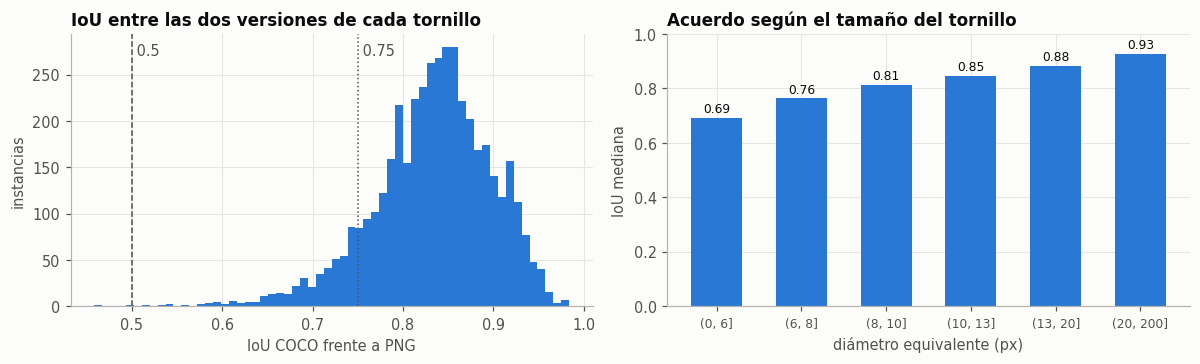

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(ins.iou_png, bins=60, color=ACENTO)
for u, ls in zip(N.UMBRALES, ['--', ':']):
    ax[0].axvline(u, color=GRIS, ls=ls, lw=1); ax[0].text(u, ax[0].get_ylim()[1] * .92, f' {u}', color=GRIS)
ax[0].set(title='IoU entre las dos versiones de cada tornillo', xlabel='IoU COCO frente a PNG', ylabel='instancias')
b = ins.assign(rango=pd.cut(ins.diametro, [0, 6, 8, 10, 13, 20, 200])).groupby('rango', observed=True).iou_png
ax[1].bar(range(len(b.median())), b.median(), color=ACENTO, width=.6)
ax[1].set_xticks(range(len(b.median()))); ax[1].set_xticklabels([str(i) for i in b.median().index], rotation=0, fontsize=8)
ax[1].set(title='Acuerdo según el tamaño del tornillo', xlabel='diámetro equivalente (px)', ylabel='IoU mediana', ylim=(0, 1))
for i, v in enumerate(b.median()): ax[1].text(i, v + .02, f'{v:.2f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

- **Área:** rasterizando el polígono por centros de píxel, el número de píxeles coincide exactamente con `area` en todas las instancias. Rasterizar con `ImageDraw.polygon` añade el contorno y engorda cada tornillo unos 19 px, lo que en un objeto de 70 px es un sesgo del 25 %. Por eso `N.etiqueta_coco` usa centros de píxel.
- **Cajas:** la convención es la misma en todas las instancias: la caja va 0,5 px por fuera del polígono, porque los vértices están en bordes de píxel. Ninguna caja deja fuera parte de su polígono.
- **Dos versiones:** el PNG no es la rasterización del COCO: es un 16 % mayor y se parece a los polígonos extendidos 1 px hacia +x, sin coincidir con ninguna transformación simple. La IoU entre ambas tiene mediana 0,84 y cae por debajo de 0,75 en el 10 % de los tornillos, sobre todo en los pequeños.
- **Techo de acuerdo:** con IoU ≥ 0,5 las dos versiones coinciden casi por completo (F1 0,9995). Con IoU ≥ 0,75, el 26 % de las imágenes ya pierde algún tornillo y el F1 baja a 0,91 sin que haya ningún error de modelo.

Estas dos versiones no son anotadores independientes (salen de la misma anotación), así que su acuerdo es una cota optimista del ruido de etiqueta: el ruido real es al menos este.

**Decisión de preprocesamiento.** La verdad de instancia es el polígono COCO rasterizado por centros de píxel. El campo `bbox` es coherente con el polígono y puede usarse tal cual. El PNG no se mezcla con COCO para entrenar: si un modelo se entrena con PNG, se evalúa contra PNG, y se declara.

**Impacto en la arquitectura.** El umbral de emparejamiento de la métrica primaria se fija en IoU ≥ 0,5: es el único en que la anotación es consistente consigo misma. AP a IoU 0,5:0,95 queda como métrica informativa, nunca para decidir.

**Riesgos.** Mezclar PNG y COCO entre entrenamiento y evaluación penalizaría a un modelo correcto en unos 0,16 de IoU por tornillo. Un umbral de 0,75 convertiría ruido de anotación en diferencias entre modelos.

#### 2.3.1 Inspección visual de instancias

Anillos alrededor de cada tornillo COCO (engrosados para que se vean a esta escala), un color por instancia, y una galería de recortes ordenados por tamaño. Sirve para comprobar alineación, tornillos sin anotar y bordes.

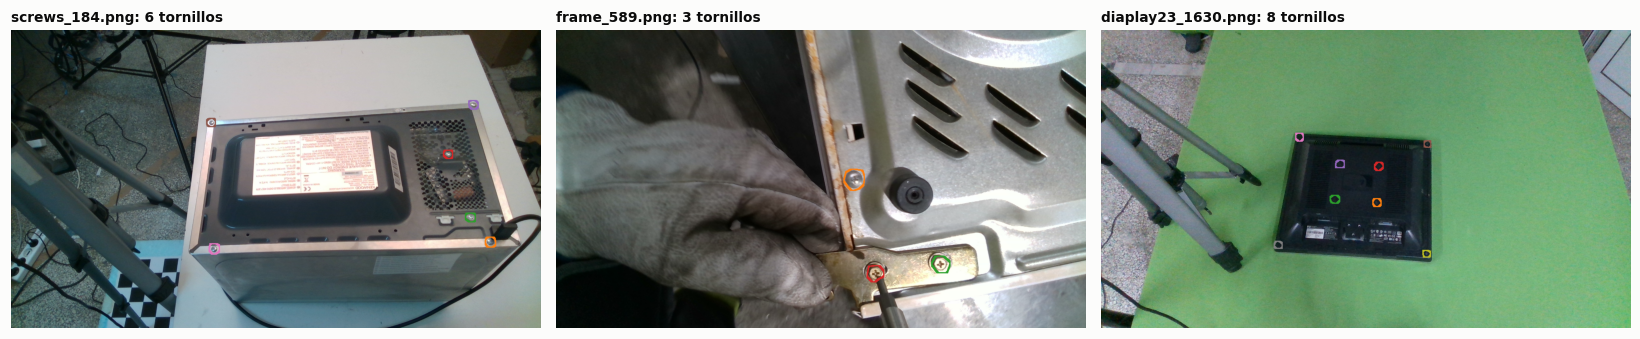

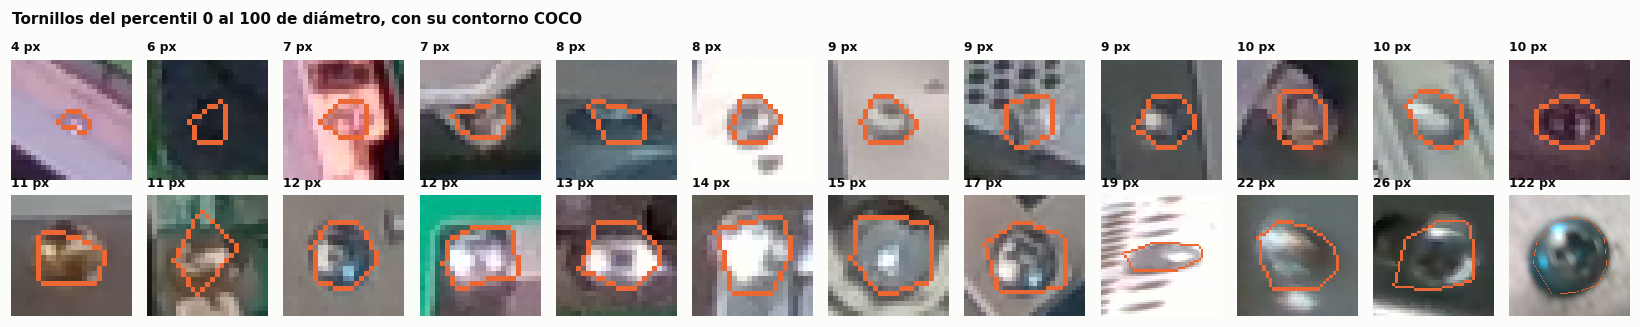

In [ ]:
por_img = N._por_archivo(coco)
rutas = dict(zip(df.archivo, df.ruta_img))
fams = ['screws', 'frame', 'diaplay']
ejemplos = [par[par.familia == f].archivo.sample(1, random_state=SEED).iloc[0] for f in fams]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.3))
cmap = plt.get_cmap('tab20')
for a, arch in zip(ax, ejemplos):
    im = np.asarray(Image.open(rutas[arch]).convert('RGB')).copy()
    lab = N.etiqueta_coco(por_img[arch])
    anillo = ndi.grey_dilation(lab, size=13)
    borde = (anillo > 0) & ~ndi.binary_dilation(lab > 0, iterations=3)
    col = (np.array([cmap((2 * i) % 20)[:3] for i in range(lab.max() + 1)]) * 255).astype(np.uint8)
    im[borde] = col[anillo[borde]]
    a.imshow(im); a.set_title(f'{arch}: {lab.max()} tornillos', fontsize=9); a.axis('off'); a.grid(False)
plt.tight_layout(); plt.show()

q = ins.sort_values('diametro').iloc[np.linspace(0, len(ins) - 1, 24).astype(int)]
fig, ax = plt.subplots(2, 12, figsize=(15, 3))
for a, f in zip(ax.ravel(), q.itertuples()):
    im = np.asarray(Image.open(rutas[f.archivo]).convert('RGB'))
    lado = int(max(24, 1.6 * max(f.w, f.h))); cx, cy = int(f.cx), int(f.cy)
    y0, x0 = max(cy - lado // 2, 0), max(cx - lado // 2, 0)
    rec = im[y0:y0 + lado, x0:x0 + lado]
    lab = N.etiqueta_coco([a_ for a_ in por_img[f.archivo] if a_['id'] == f.id])[y0:y0 + lado, x0:x0 + lado]
    rec = rec.copy(); rec[find_boundaries(lab, mode='outer')] = (235, 104, 52)
    a.imshow(rec, interpolation='nearest'); a.set_title(f'{f.diametro:.0f} px', fontsize=8); a.axis('off'); a.grid(False)
fig.suptitle('Tornillos del percentil 0 al 100 de diámetro, con su contorno COCO', x=.01, ha='left', fontsize=10, fontweight='bold')
plt.tight_layout(h_pad=1.2); plt.show()

Los contornos rodean las cabezas de tornillo, pero son toscos: polígonos de pocos lados que no siguen el borde circular, sobre todo en los pequeños. Por debajo de unos 8 px de diámetro, el tornillo es una mancha de pocos píxeles sin estructura interna y la frontera exacta es ambigua, lo que explica la caída de acuerdo de la figura anterior.

**Decisión de preprocesamiento.** Ninguno: no aparecen máscaras desplazadas ni instancias vacías que obliguen a filtrar imágenes.

**Impacto en la arquitectura.** Los tornillos pequeños solo se distinguen por contraste local, así que la red debe conservar la resolución nativa en las primeras capas: nada de reducciones agresivas en la entrada ni de un primer bloque con paso 4.

**Riesgos.** Queda sin medir la tasa de tornillos sin anotar, que exigiría una auditoría manual (pendiente del README). Un tornillo sin anotar cuenta como falso positivo del modelo.

### 2.4 La variable objetivo: número de instancias por imagen

Instancias por imagen: media 4.65, mediana 4, mínimo 1, máximo 17
Índice de dispersión (varianza / media): 2.19  (1 en un proceso de Poisson)
Asimetría 1.06 | curtosis en exceso 0.66


,imagenes,instancias,media,mediana,maximo,pct_instancias
familia,,,,,,
screws,202,1478,7.32,7.0,16,33.61
diaplay,109,622,5.71,4.0,8,14.14
eco,136,595,4.38,4.0,11,13.53
frame,158,552,3.49,2.0,17,12.55
pc,156,484,3.10,3.0,4,11.01
micro,100,407,4.07,4.0,8,9.25
tower,53,141,2.66,2.0,11,3.21
numerico,30,118,3.93,5.0,6,2.68
screen,1,1,1.00,1.0,1,0.02


Fracción de fondo con la verdad COCO: 99.919 % (razón fondo:tornillo 1,228:1)


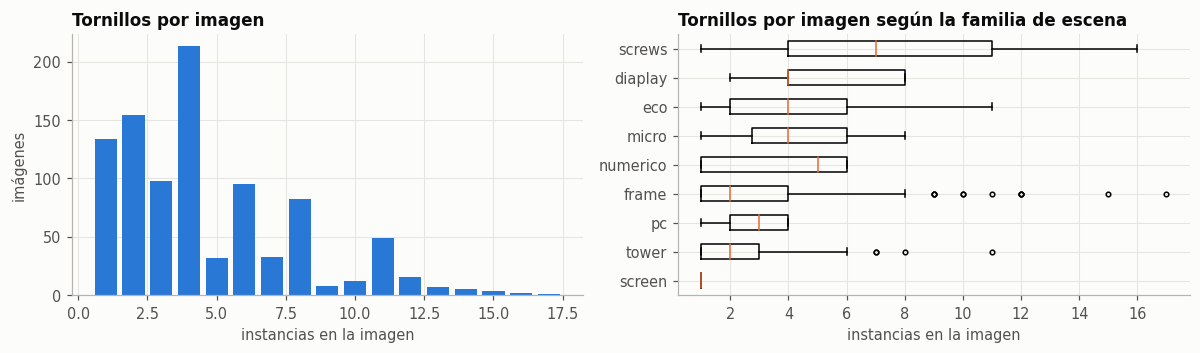

In [ ]:
n_img = ins.groupby('archivo').size().reindex(par.archivo, fill_value=0)
pi = par.assign(n=n_img.values)
r = pi.n.describe()
print(f'Instancias por imagen: media {r["mean"]:.2f}, mediana {r["50%"]:.0f}, mínimo {r["min"]:.0f}, máximo {r["max"]:.0f}')
print(f'Índice de dispersión (varianza / media): {pi.n.var() / pi.n.mean():.2f}  (1 en un proceso de Poisson)')
print(f'Asimetría {stats.skew(pi.n):.2f} | curtosis en exceso {stats.kurtosis(pi.n):.2f}')
tab = pi.groupby('familia').n.agg(imagenes='size', instancias='sum', media='mean', mediana='median', maximo='max')
tab['pct_instancias'] = 100 * tab.instancias / tab.instancias.sum()
display(tab.sort_values('instancias', ascending=False).round(2))
fondo = 1 - ins.area_coco.sum() / (len(df) * E.H * E.W)
print(f'Fracción de fondo con la verdad COCO: {100 * fondo:.3f} % (razón fondo:tornillo {fondo / (1 - fondo):,.0f}:1)')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].bar(*np.unique(pi.n, return_counts=True), color=ACENTO, width=.8)
ax[0].set(title='Tornillos por imagen', xlabel='instancias en la imagen', ylabel='imágenes')
o = tab.sort_values('media').index
ax[1].boxplot([pi.n[pi.familia == f] for f in o], vert=False, labels=o, widths=.5,
              medianprops={'color': '#eb6834'}, flierprops={'markersize': 3})
ax[1].set(title='Tornillos por imagen según la familia de escena', xlabel='instancias en la imagen')
plt.tight_layout(); plt.show()

La imagen típica tiene 4 tornillos y ninguna pasa de 17. La sobredispersión es moderada y viene sobre todo de la familia `screws`, que concentra un tercio de las instancias con imágenes de hasta 16 tornillos. La familia `pc` nunca pasa de 4.

El desbalance a nivel de píxel es extremo (fondo del orden del 99,9 %), pero a nivel de instancia no hay clases que equilibrar: la dificultad es encontrar todos los objetos, no distinguir entre ellos.

**Decisión de preprocesamiento.** No se remuestrea por número de instancias. Sí se muestrean los parches de entrenamiento centrados en tornillos (por ejemplo, la mitad de los parches con al menos una instancia), porque un parche de 512×512 tomado al azar cae a menudo en fondo puro.

**Impacto en la arquitectura.** Un límite de 100 detecciones por imagen cubre de sobra el máximo de 17. La pérdida no puede ser solo entropía cruzada por píxel: con este desbalance, el óptimo trivial es predecir fondo. Se usa Dice + entropía cruzada (o focal).

**Riesgos.** Como `screws` aporta un tercio de las instancias, un F1 agregado sobre todas las instancias reflejaría sobre todo esa familia. El F1 se promedia por imagen y se reporta además por familia.

### 2.5 Tamaño y forma de las instancias

Diámetro equivalente (px): {'count': 4398.0, 'mean': 12.5, 'std': 7.0, 'min': 3.6, '1%': 5.0, '5%': 6.3, '25%': 8.5, '50%': 10.6, '75%': 13.9, '95%': 25.2, '99%': 37.3, 'max': 121.8}
Clases de tamaño COCO (%): {'small': 98.84, 'medium': 1.14, 'large': 0.02}
Instancias con área < 8x8 px: 30.5 %   < 16x16 px: 85.4 %
Relleno de la caja: mediana 0.76 (pi/4 = 0.79 para un círculo) | aspecto: p1 0.62, p99 2.00
Kruskal-Wallis del diámetro entre familias: H = 2030.2, p = 0.00e+00 (instancias no independientes: es descriptivo)


,size,median,p90
familia,,,
diaplay,622,7.4,10.2
pc,484,10.0,13.4
screws,1478,10.0,15.5
eco,595,10.2,12.7
numerico,118,12.1,15.6
frame,552,17.8,29.4
tower,141,18.4,27.0
micro,407,18.5,25.9
screen,1,19.5,19.5


La mitad más pequeña de los tornillos aporta el 17.4 % de los píxeles de tornillo.


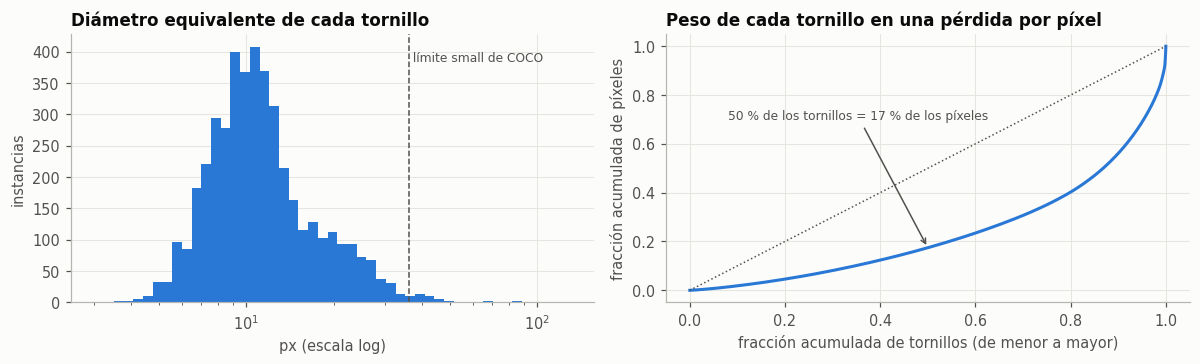

In [ ]:
d = ins.diametro
print('Diámetro equivalente (px):', d.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_dict())
clases = pd.cut(ins.area_coco, [0, 32**2, 96**2, np.inf], labels=['small', 'medium', 'large'], right=False)
print('Clases de tamaño COCO (%):', (100 * clases.value_counts(normalize=True)).round(2).to_dict())
print(f'Instancias con área < 8x8 px: {100 * (ins.area_coco < 64).mean():.1f} %   < 16x16 px: {100 * (ins.area_coco < 256).mean():.1f} %')
llen = ins.area_coco / ((ins.px_x1 - ins.px_x0) * (ins.px_y1 - ins.px_y0))
asp = (ins.px_x1 - ins.px_x0) / (ins.px_y1 - ins.px_y0)
print(f'Relleno de la caja: mediana {llen.median():.2f} (pi/4 = {np.pi/4:.2f} para un círculo) | aspecto: p1 {asp.quantile(.01):.2f}, p99 {asp.quantile(.99):.2f}')
H, p = stats.kruskal(*[g.diametro for _, g in ins.groupby('familia') if len(g) > 5])
print(f'Kruskal-Wallis del diámetro entre familias: H = {H:.1f}, p = {p:.2e} (instancias no independientes: es descriptivo)')
display(ins.groupby('familia').diametro.agg(['size', 'median', lambda s: s.quantile(.9)]).rename(columns={'<lambda_0>': 'p90'}).sort_values('median').round(1))

o = np.sort(ins.area_coco.to_numpy())
cum_px = np.cumsum(o) / o.sum()
mitad = np.searchsorted(np.arange(1, len(o) + 1) / len(o), .5)
print(f'La mitad más pequeña de los tornillos aporta el {100 * cum_px[mitad]:.1f} % de los píxeles de tornillo.')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(d, bins=np.logspace(np.log10(3), np.log10(130), 50), color=ACENTO)
ax[0].set_xscale('log'); ax[0].axvline(np.sqrt(4 * 32**2 / np.pi), color=GRIS, ls='--', lw=1)
ax[0].text(np.sqrt(4 * 32**2 / np.pi), ax[0].get_ylim()[1] * .9, ' límite small de COCO', color=GRIS, fontsize=8)
ax[0].set(title='Diámetro equivalente de cada tornillo', xlabel='px (escala log)', ylabel='instancias')
ax[1].plot(np.arange(1, len(o) + 1) / len(o), cum_px, color=ACENTO, lw=2)
ax[1].plot([0, 1], [0, 1], color=GRIS, lw=1, ls=':')
ax[1].set(title='Peso de cada tornillo en una pérdida por píxel', xlabel='fracción acumulada de tornillos (de menor a mayor)',
          ylabel='fracción acumulada de píxeles')
ax[1].annotate(f'50 % de los tornillos = {100 * cum_px[mitad]:.0f} % de los píxeles', (.5, cum_px[mitad]), (.08, .7),
               arrowprops={'arrowstyle': '->', 'color': GRIS}, fontsize=8, color=GRIS)
plt.tight_layout(); plt.show()

El 98,8 % de las instancias son *small* en la convención COCO (menos de 32×32 px) y la mediana del diámetro es unos 11 px. Son objetos compactos y casi circulares: el relleno de la caja ronda $\pi/4$ y el aspecto se mantiene entre 0,6 y 2.

El tamaño depende de la familia: `diaplay` tiene los tornillos más pequeños (mediana de 7 px) y `frame`, `tower` y `micro` los mayores (unos 18 px). La consecuencia más importante está a la derecha: en una pérdida por píxel, la mitad más pequeña de los tornillos pesa muy poco, aunque en el F1 de instancia cada tornillo cuenta lo mismo.

**Decisión de preprocesamiento.** Sin reescalado hacia abajo (sección 2.9). Augmentations de escala limitadas a ±20 %, para no llevar los tornillos pequeños por debajo de unos 5 px.

**Impacto en la arquitectura.** La pérdida debe dar a cada instancia un peso parecido: Dice por instancia, ponderación por píxel inversa al área del tornillo o focal. En detectores tipo Mask R-CNN (Entregable 2) haría falta un nivel de paso 4 (P2) y anclas de 8 a 32 px; con paso 8, la mediana del tornillo ocupa poco más de una celda.

**Riesgos.** Con una pérdida por píxel sin ponderar, el modelo puede alcanzar buen Dice de píxel y perder la mayoría de los tornillos pequeños. Por eso el Dice de píxel no sirve como métrica primaria en este planteamiento.

### 2.6 Separación entre instancias: ¿basta un etiquetado de componentes conexas?

El enunciado fija como modelos base una FCN sencilla, un codificador-decodificador básico y una U-Net reducida. Estos modelos predicen una máscara por píxel, y sus instancias salen de las componentes conexas de esa máscara. Esto solo funciona si los tornillos no se tocan y si sigue funcionando cuando el modelo engorda un poco los bordes.

In [ ]:
print('Solapes entre polígonos de una misma imagen: ninguno (máscara de etiquetas sin conflictos).')
print('Instancias cuya componente PNG contiene a otra instancia:', int((ins.instancias_en_componente > 1).sum()))
print('Distancia entre centros al vecino más cercano (px):', ins.dist_vecino.describe(percentiles=[.01, .05, .5]).round(1).to_dict())

radios = [0, 1, 2, 3, 5, 8]
perdidas = {r: 0 for r in radios}
imgs_fus = {r: 0 for r in radios}
for arch, anns in por_img.items():
    b = N.etiqueta_coco(anns) > 0
    for r in radios:
        m = ndi.binary_dilation(b, np.ones((3, 3)), iterations=r) if r else b
        n = measure.label(m, connectivity=2).max()
        perdidas[r] += len(anns) - n
        imgs_fus[r] += n < len(anns)
dil = pd.DataFrame({'instancias fusionadas': perdidas, '% de instancias': {r: 100 * perdidas[r] / len(ins) for r in radios},
                    'imagenes afectadas': imgs_fus})
dil.index.name = 'dilatación (px)'
display(dil.round(2))
print('Área mínima de un tornillo:', ins.area_coco.min(), 'px | percentil 1:', ins.area_coco.quantile(.01), 'px')

Solapes entre polígonos de una misma imagen: ninguno (máscara de etiquetas sin conflictos).
Instancias cuya componente PNG contiene a otra instancia: 0
Distancia entre centros al vecino más cercano (px): {'count': 4264.0, 'mean': 138.1, 'std': 105.6, 'min': 14.1, '1%': 37.4, '5%': 47.3, '50%': 103.0, 'max': 1017.6}


,instancias fusionadas,% de instancias,imagenes afectadas
dilatación (px),,,
0,0,0.00,0
1,0,0.00,0
2,1,0.02,1
3,1,0.02,1
5,4,0.09,4
8,11,0.25,10


Área mínima de un tornillo: 10 px | percentil 1: 20.0 px


Ningún par de tornillos se toca ni se solapa, y cada instancia COCO corresponde a una sola componente del PNG. Con la verdad de referencia, las componentes conexas recuperan exactamente las instancias.

La tabla simula un modelo que engorda todas las máscaras unos píxeles. Con 3 px de dilatación se fusiona un solo par de tornillos, y con 8 px solo 11 de 4.398 (0,25 %). El etiquetado por componentes es robusto a errores de borde mucho mayores que los esperables.

**Decisión de preprocesamiento.** Postproceso común a los tres modelos base: binarizar la probabilidad (umbral elegido en validación), eliminar componentes de menos de 5 px (el tornillo más pequeño tiene 10 px) y etiquetar componentes conexas con 8-vecindad. Está implementado en `N.etiqueta_mascara(mascara, area_min=5)`.

**Impacto en la arquitectura.** Los modelos base del enunciado (FCN, codificador-decodificador, U-Net reducida) son válidos para instancias sin cambios en la arquitectura. Modelos con cabeza de instancias (Mask R-CNN, YOLO-seg) quedan para el benchmark del Entregable 2.

**Riesgos.** El riesgo de fusión es bajo. El riesgo real del postproceso es el contrario: una predicción fragmentada en varias manchas genera falsos positivos. El área mínima y el umbral se ajustan en validación; si la fragmentación aparece en el piloto, se añade un cierre morfológico igual para los tres modelos.

### 2.7 Posición de las instancias en la imagen

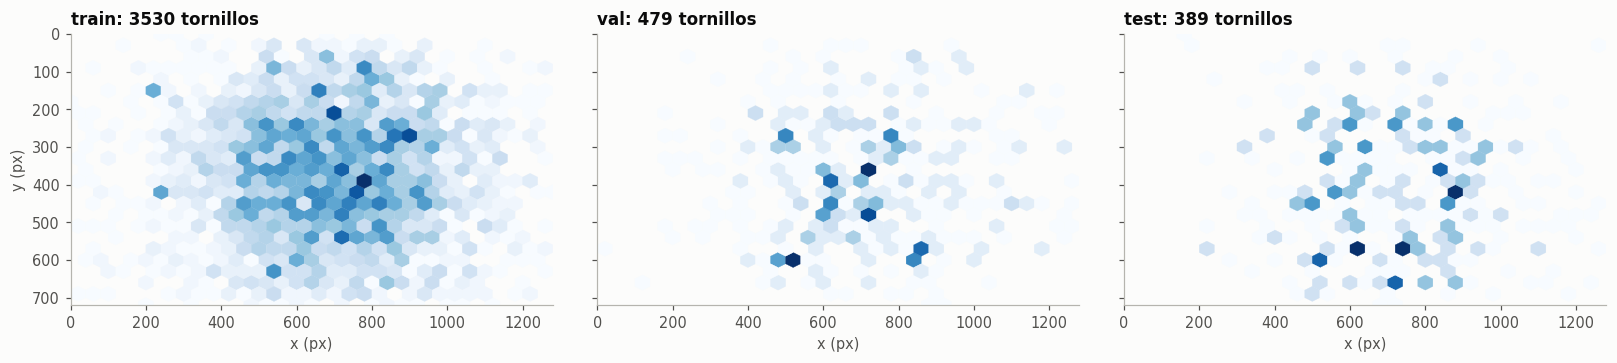

Instancias que tocan el borde de la imagen: 0
train: centro medio (691, 371) px, desviación (222, 163)
val: centro medio (705, 391) px, desviación (222, 160)
test: centro medio (732, 404) px, desviación (220, 169)


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for a, k in zip(ax, SPLITS):
    s = ins[ins.split == k]
    a.hexbin(s.cx, s.cy, gridsize=(32, 12), extent=(0, E.W, 0, E.H), cmap='Blues', mincnt=1, linewidths=.2)
    a.set(xlim=(0, E.W), ylim=(E.H, 0), title=f'{k}: {len(s)} tornillos', xlabel='x (px)'); a.set_aspect('equal'); a.grid(False)
ax[0].set_ylabel('y (px)')
plt.tight_layout(); plt.show()
borde = (ins.px_x0 <= 1) | (ins.px_y0 <= 1) | (ins.px_x1 >= E.W - 1) | (ins.px_y1 >= E.H - 1)
print('Instancias que tocan el borde de la imagen:', int(borde.sum()))
for k in SPLITS:
    s = ins[ins.split == k]
    print(f'{k}: centro medio ({s.cx.mean():.0f}, {s.cy.mean():.0f}) px, desviación ({s.cx.std():.0f}, {s.cy.std():.0f})')

Los tornillos ocupan casi toda la imagen, con más densidad en la franja central, y ninguno toca el borde. La posición viene de cómo se colocó el aparato frente a la cámara en cada escena, así que las diferencias entre particiones reflejan escenas distintas, no un sesgo de anotación.

**Decisión de preprocesamiento.** Volteos horizontales y verticales y rotaciones de 90° son admisibles: un tornillo no tiene orientación preferente y las escenas cambian de encuadre. No se necesita *padding* especial en los bordes.

**Impacto en la arquitectura.** No hace falta codificar la posición: las arquitecturas convolucionales invariantes a la traslación son adecuadas.

**Riesgos.** Si el modelo aprende la posición típica de los tornillos de cada escena, test (con escenas nuevas) lo penalizará. Esto es deseable: mide la generalización a escenas no vistas.

### 2.8 Sensibilidad de la IoU al desplazamiento: elección del umbral

Para objetos de 10 px, un error de un píxel cambia mucho la IoU. Se mide la IoU de cada tornillo consigo mismo desplazado 1, 2 y 3 px.

IoU mediana de un tornillo consigo mismo desplazado:


,1 px,2 px,3 px
diámetro (px),,,
"(0, 6]",0.647,0.400,0.227
"(6, 8]",0.719,0.508,0.344
"(8, 10]",0.765,0.581,0.432
"(10, 13]",0.807,0.648,0.515
"(13, 20]",0.853,0.726,0.616
"(20, 200]",0.903,0.816,0.736


Fracción de tornillos que seguirían siendo acierto tras desplazarse:


,1 px,2 px,3 px
IoU >= 0.5,99.6,88.1,49.0
IoU >= 0.75,76.6,16.2,4.5


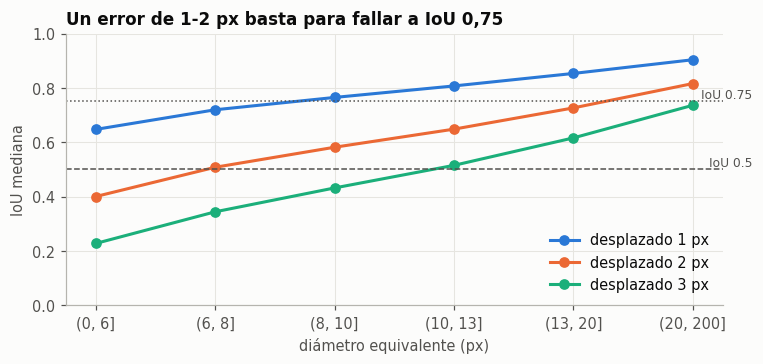

In [ ]:
rango = pd.cut(ins.diametro, [0, 6, 8, 10, 13, 20, 200])
sens = ins.groupby(rango, observed=True)[['iou_auto1', 'iou_auto2', 'iou_auto3']].median()
sens.columns = ['1 px', '2 px', '3 px']; sens.index.name = 'diámetro (px)'
print('IoU mediana de un tornillo consigo mismo desplazado:'); display(sens.round(3))
tabla = pd.DataFrame({f'{s} px': {f'IoU >= {u}': (ins[f'iou_auto{s}'] >= u).mean() for u in N.UMBRALES} for s in (1, 2, 3)})
print('Fracción de tornillos que seguirían siendo acierto tras desplazarse:'); display((100 * tabla).round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(sens))
for j, (c, col) in enumerate(zip(sens.columns, ['#2a78d6', '#eb6834', '#1baf7a'])):
    ax.plot(x, sens[c], marker='o', lw=2, color=col, label=f'desplazado {c}')
for u, ls in zip(N.UMBRALES, ['--', ':']):
    ax.axhline(u, color=GRIS, ls=ls, lw=1); ax.text(len(sens) - .5, u + .01, f'IoU {u}', color=GRIS, fontsize=8, ha='right')
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in sens.index])
ax.set(title='Un error de 1-2 px basta para fallar a IoU 0,75', xlabel='diámetro equivalente (px)', ylabel='IoU mediana', ylim=(0, 1))
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

A IoU 0,75, un desplazamiento de 2 px ya hace fallar a la mayoría de los tornillos. A IoU 0,5, el acierto aguanta 1 px en casi todos y 2 px en la mayoría. Junto con el techo de acuerdo de la sección 2.3 (F1 0,9995 a 0,5 frente a 0,91 a 0,75), esto fija el umbral.

**Decisión de preprocesamiento.** Ninguna sobre las imágenes. Las máscaras de verdad no se suavizan ni se dilatan.

**Impacto en la arquitectura.** Métrica primaria: F1 de instancia por imagen con emparejamiento húngaro e IoU ≥ 0,5 (`N.metricas_instancia`). Secundarias: SQ y PQ al mismo umbral, AP50 de máscara, error absoluto en el conteo, y Dice e IoU de píxel por imagen (las que pide el enunciado). AP 0,5:0,95 y F1 a 0,75 se reportan como informativas.

**Riesgos.** AP 0,5:0,95, el estándar de COCO, está dominada aquí por errores de 1-2 px y por el ruido de anotación. Comparar con trabajos que la usan requiere reportarla, pero no debe decidir el ranking.

### 2.9 Resolución de entrada y teselado

In [ ]:
for esc in (1, .75, .5, .4):
    dd = ins.diametro * esc
    print(f'Escala {esc:>4}: diámetro mediano {dd.median():5.1f} px | tornillos con menos de 4 px: {100 * (dd < 4).mean():5.1f} % | menos de 6 px: {100 * (dd < 6).mean():5.1f} %')
tes = pd.DataFrame([N.cobertura_teselas(ins, t, s) for t in (256, 384, 512) for s in (0, 32, 64)])
print('\nVentanas sobre la imagen 1280x720 (la última ventana se ajusta al borde):'); display(tes.round(4))
print('Lado máximo de un tornillo:', int(max((ins.px_x1 - ins.px_x0).max(), (ins.px_y1 - ins.px_y0).max())), 'px | percentil 99:',
      int(np.percentile(np.maximum(ins.px_x1 - ins.px_x0, ins.px_y1 - ins.px_y0), 99)), 'px')

Escala    1: diámetro mediano  10.6 px | tornillos con menos de 4 px:   0.1 % | menos de 6 px:   4.1 %
Escala 0.75: diámetro mediano   8.0 px | tornillos con menos de 4 px:   1.6 % | menos de 6 px:  20.0 %
Escala  0.5: diámetro mediano   5.3 px | tornillos con menos de 4 px:  20.0 % | menos de 6 px:  63.8 %
Escala  0.4: diámetro mediano   4.3 px | tornillos con menos de 4 px:  42.8 % | menos de 6 px:  78.9 %

Ventanas sobre la imagen 1280x720 (la última ventana se ajusta al borde):


,tam,solape,ventanas,cortadas_rejilla,cubiertas_ventana
0,256,0,15,0.0923,0.9268
1,256,32,24,0.0923,0.9977
2,256,64,28,0.0923,0.9998
3,384,0,8,0.0573,0.9704
4,384,32,8,0.0573,0.9995
5,384,64,12,0.0573,1.0000
6,512,0,6,0.0452,0.9798
7,512,32,6,0.0452,1.0000
8,512,64,6,0.0452,1.0000


Lado máximo de un tornillo: 125 px | percentil 99: 41 px


Reducir la imagen a la mitad dejaría muchos tornillos por debajo de 6 px de diámetro, donde ya no se distinguen (sección 2.3.1). Con ventanas de 512×512 y un solape de 32 px o más, todos los tornillos caben enteros en al menos una ventana. Sin solape, el 2 % queda partido entre ventanas y se contaría como dos instancias o como ninguna.

**Decisión de preprocesamiento.** Entrenamiento con parches de 512×512 a resolución nativa. Inferencia por ventana deslizante de 512 con solape de 64 px, más que el lado de cualquier tornillo salvo los mayores. Las probabilidades se combinan en la imagen completa antes de etiquetar componentes, nunca por ventana.

**Impacto en la arquitectura.** Con entrada de 512, una U-Net reducida de 4 niveles llega a paso 16 en el cuello y conserva paso 1 y 2 en las conexiones de salto. Un tornillo de 11 px sobrevive así en el decodificador.

**Riesgos.** Etiquetar por ventana y luego unir duplicaría los tornillos del solape. Además, el solape no debe cruzar particiones: las ventanas se cortan siempre dentro de una misma imagen.

### 2.10 Partición: consistencia a nivel de instancia

Se usa la partición agrupada congelada del notebook 01 (`results/eda/particion.csv`, 744/93/108 imágenes, 186 grupos sin compartir). Aquí no se regenera: solo se comprueba que la variable objetivo de instancias está repartida de forma comparable.

Las instancias de una imagen, y las imágenes de un grupo, no son independientes. Por eso las pruebas permutan grupos enteros entre particiones y usan una estadística por imagen.

,imagenes,grupos,instancias,inst_por_imagen,diam_mediano,frac_pequenos,pct_instancias
split,,,,,,,
train,744,146,3530,4.745,11.284,0.174,80.264
val,93,26,479,5.151,12.715,0.161,10.891
test,108,14,389,3.602,10.846,0.302,8.845


,H,p_permutacion_grupos,p_Holm
n,17.2200,0.1910,0.5729
diam_mediano,4.7186,0.8484,1.0000
frac_pequenos,6.5782,0.7906,1.0000


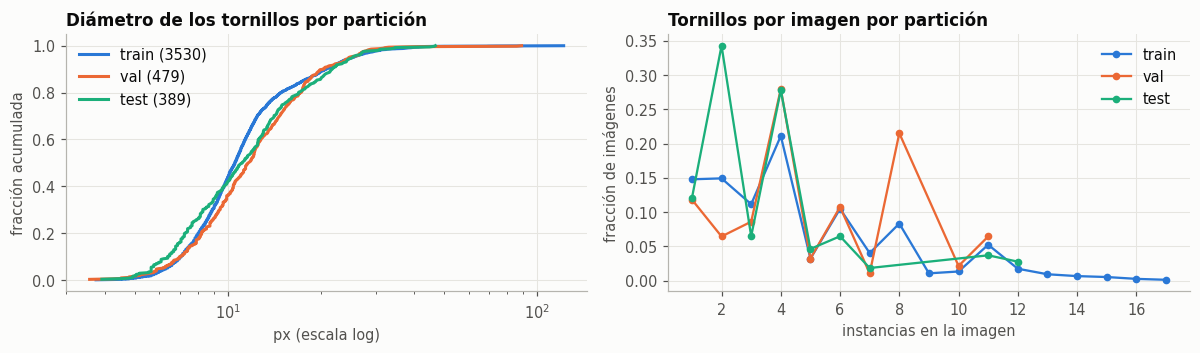

split     train   val  test
familia                    
diaplay    14.9   7.5  15.2
eco        12.1  23.4  14.4
frame      12.9   9.8  12.6
micro       8.6   9.4  14.9
numerico    3.3   0.0   0.0
pc         10.4  12.1  14.9
screen      0.0   0.0   0.0
screws     35.5  30.3  20.8
tower       2.2   7.5   7.2


In [ ]:
pi['diam_mediano'] = ins.groupby('archivo').diametro.median().reindex(pi.archivo).values
pi['frac_pequenos'] = ins.assign(p=ins.diametro < 8).groupby('archivo').p.mean().reindex(pi.archivo).values
resumen = pi.groupby('split').agg(imagenes=('archivo', 'size'), grupos=('grupo', 'nunique'), instancias=('n', 'sum'),
    inst_por_imagen=('n', 'mean'), diam_mediano=('diam_mediano', 'median'), frac_pequenos=('frac_pequenos', 'mean')).loc[SPLITS]
resumen['pct_instancias'] = 100 * resumen.instancias / resumen.instancias.sum()
display(resumen.round(3))

def permuta_grupos(col, n=5000):
    """p-valor de Kruskal-Wallis entre particiones, permutando la etiqueta de partición por grupos."""
    g = pi.groupby('grupo').agg(split=('split', 'first'))
    idx = pi.grupo.map({k: i for i, k in enumerate(g.index)}).to_numpy()
    v = pi[col].to_numpy()
    def H(lab):
        s = lab[idx]
        return stats.kruskal(*[v[s == k] for k in SPLITS]).statistic
    lab0 = g.split.to_numpy()
    h0 = H(lab0)
    hs = np.array([H(rng.permutation(lab0)) for _ in range(n)])
    return h0, (1 + (hs >= h0).sum()) / (n + 1)

pr = pd.DataFrame({c: dict(zip(['H', 'p_permutacion_grupos'], permuta_grupos(c))) for c in ['n', 'diam_mediano', 'frac_pequenos']}).T
o_ = np.argsort(pr.p_permutacion_grupos.to_numpy()); m_ = len(o_)
holm = np.maximum.accumulate(np.minimum(1, (m_ - np.arange(m_)) * pr.p_permutacion_grupos.to_numpy()[o_]))
pr['p_Holm'] = np.empty(m_); pr.iloc[o_, pr.columns.get_loc('p_Holm')] = holm
display(pr.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for k in SPLITS:
    s = np.sort(ins[ins.split == k].diametro)
    ax[0].plot(s, np.arange(1, len(s) + 1) / len(s), color=COLOR[k], lw=2, label=f'{k} ({len(s)})')
    c = pi[pi.split == k].n.value_counts(normalize=True).sort_index()
    ax[1].plot(c.index, c.values, marker='o', ms=4, color=COLOR[k], lw=1.5, label=k)
ax[0].set_xscale('log'); ax[0].set(title='Diámetro de los tornillos por partición', xlabel='px (escala log)', ylabel='fracción acumulada')
ax[1].set(title='Tornillos por imagen por partición', xlabel='instancias en la imagen', ylabel='fracción de imágenes')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
print(pd.crosstab(ins.familia, ins.split, normalize='columns').loc[:, SPLITS].mul(100).round(1))

Test tiene menos tornillos por imagen (3,6 frente a 4,7 en train) y más tornillos pequeños, porque `screws` pesa menos en test (21 % de las instancias frente a 36 %). La permutación por grupos no distingue estas diferencias de las que produciría repartir los mismos grupos al azar (p = 0,19 para el conteo, 0,85 y 0,79 para el tamaño; tras Holm, p ≥ 0,57). Con 14 grupos en test, cualquier reparto deja diferencias visibles: no es un defecto que se pueda corregir sin romper la agrupación.

**Decisión de preprocesamiento.** La partición congelada se mantiene. No se reequilibra por número de instancias, porque eso exigiría mover imágenes de un mismo grupo entre particiones y reintroducir la fuga del split oficial.

**Impacto en la arquitectura.** Ninguno directo. El umbral de binarización y el área mínima del postproceso se ajustan en validación, nunca en test.

**Riesgos.** Las diferencias de composición entre particiones (familias y número de tornillos) hacen que el F1 de test dependa de pocos grupos. El intervalo de confianza debe remuestrear grupos (bootstrap por grupos), no solo imágenes.

### 2.11 Referencias sin aprendizaje

Antes de los modelos base conviene fijar las dos cotas que acotan cualquier resultado:

- **Suelo:** predecir solo fondo. Su exactitud de píxel ronda el 99,9 %, pero su F1 de instancia es 0. Por eso la exactitud de píxel no puede ser métrica de decisión.
- **Techo de anotación:** usar la otra versión de la anotación (PNG) como predicción. Ningún modelo puede superar de forma creíble este acuerdo.

In [ ]:
pix_acc = 1 - ins.groupby('archivo').area_coco.sum() / (E.H * E.W)
ref = pd.DataFrame({
    'solo fondo': {'F1 instancia (IoU 0,5)': 0.0, 'PQ (IoU 0,5)': 0.0, 'exactitud de píxel': pix_acc.mean()},
    'anotación PNG': {'F1 instancia (IoU 0,5)': acu['f1_0.5'].mean(), 'PQ (IoU 0,5)': acu['pq_0.5'].mean(), 'exactitud de píxel': np.nan}})
display(ref.round(4))

,solo fondo,anotación PNG
"F1 instancia (IoU 0,5)",0.0000,0.9995
"PQ (IoU 0,5)",0.0000,0.8419
exactitud de píxel,0.9992,NaN


El F1 de instancia separa con claridad el modelo trivial (0) del techo (≈1), mientras que la exactitud de píxel los deja casi iguales. La PQ tiene un techo de 0,84 porque incluye la calidad del contorno, limitada por el ruido de anotación de la sección 2.3.

**Decisión de preprocesamiento.** Ninguna.

**Impacto en la arquitectura.** El margen útil para comparar modelos está en el F1 de instancia, entre 0 y casi 1. La PQ se interpreta respecto a su techo de 0,84, no respecto a 1.

**Riesgos.** Reportar la exactitud de píxel como resultado principal haría parecer bueno cualquier modelo. Se reporta solo porque el enunciado la lista.

### 2.12 Implicaciones para los tres modelos base

Este notebook no implementa modelos. Lo que sigue resume las restricciones que el EDA impone a quien los implemente:

| Aspecto | Decisión derivada del EDA | Sección |
|---|---|---|
| Verdad de referencia | Polígonos COCO rasterizados por centros de píxel (`N.etiqueta_coco`) | 2.3 |
| Familias de modelos base | FCN sencilla, codificador-decodificador básico y U-Net reducida, con salida binaria y postproceso de componentes conexas; la selección final sale de la revisión de literatura | 2.6 |
| Postproceso | Umbral ajustado en validación, eliminar componentes de menos de 5 px y etiquetar con 8-vecindad (`N.etiqueta_mascara`) | 2.6 |
| Entrada | Parches de 512×512 a resolución nativa; la mitad de los parches centrados en tornillos | 2.4, 2.9 |
| Inferencia | Ventana deslizante de 512 con solape de 64 px; etiquetado sobre la imagen completa | 2.9 |
| Pérdida | Dice + entropía cruzada o focal, con peso por instancia | 2.4, 2.5 |
| Augmentations | Volteos, rotaciones de 90°, escala ±20 % y fotométricas; las mismas sobre imagen y máscara | 2.5, 2.7 |
| Normalización | `results/eda/normalizacion_train.json` (calculada solo con train en el 01) | 2.01 |
| Métrica primaria | F1 de instancia por imagen, IoU ≥ 0,5 (`N.metricas_instancia`) | 2.8 |
| Inferencia estadística | Wilcoxon o t pareado sobre el F1 por imagen; IC por bootstrap de grupos | 2.10 |

> **Nota de integración: qué se implementó (sección 4).**
>
> | Aspecto | Implementado en los modelos base |
> |---|---|
> | Verdad de referencia | Igual: polígonos COCO, rasterizados con el mismo código para los tres modelos |
> | Familias de modelos base | Mask R-CNN, YOLOv8-seg y SOLOv2, extraídos de la literatura (sección 3) |
> | Postproceso | No hace falta el de componentes conexas: los tres modelos producen instancias directamente. El umbral de confianza se ajusta en validación |
> | Entrada | Imagen completa de 1280×720, sin reescalar (coherente con la sección 2.9), en lugar de parches de 512 |
> | Inferencia | Imagen completa, sin ventana deslizante |
> | Pérdida | La de cada modelo en su implementación de referencia |
> | Aumentos | Volteo horizontal en Mask R-CNN y SOLOv2; los de ultralytics por defecto en YOLOv8-seg |
> | Normalización | La de cada modelo preentrenado en COCO |
> | Métrica primaria | Igual: F1 de instancia por imagen, IoU ≥ 0,5 |
> | Inferencia estadística | Unidad = grupo (14 en prueba): Friedman, Wilcoxon por grupo con Holm y bootstrap de grupos (sección 5.3) |

### 2.13 Declaración a priori y veredicto

In [ ]:
decl = {
    'fecha': '2026-11-07',
    'sustituye_a': 'declaracion_a_priori.json (orientación semántica) en métrica primaria y verdad de referencia; partición y unidad de independencia se heredan sin cambios',
    'tipo_problema': '8. Segmentación de imágenes (variante de instancias)',
    'verdad_referencia': 'Polígonos COCO rasterizados por centros de píxel (wdsd_e1.instancias.etiqueta_coco); el PNG no se usa para evaluar',
    'metrica_primaria': {'nombre': 'F1 de instancia por imagen', 'emparejamiento': 'húngaro por IoU de máscara', 'umbral_iou': 0.5,
                         'agregacion': 'media sobre imágenes', 'implementacion': 'wdsd_e1.instancias.metricas_instancia'},
    'metricas_secundarias': ['SQ y PQ a IoU 0,5', 'AP50 de máscara', 'error absoluto en el número de tornillos por imagen',
                             'Dice e IoU de píxel por imagen', 'exactitud de píxel y mIoU (solo porque el enunciado las lista)',
                             'F1 por familia de escena'],
    'metricas_informativas': ['AP 0,5:0,95 de máscara', 'F1 a IoU 0,75'],
    'delta': 0.03, 'delta_estado': 'provisional hasta el estudio piloto',
    'alpha': 0.05,
    'unidad_independencia': 'grupo de escena (columna grupo de particion.csv)',
    'particion': {'archivo': 'results/eda/particion.csv', 'tamanos': dec01['particion']['tamanos'],
                  'sha256': dec01['particion']['sha256'], 'instancias': resumen.instancias.astype(int).to_dict()},
    'postproceso': {'binarizacion': 'umbral elegido en validación', 'area_minima_px': 5, 'conectividad': 8},
    'inferencia': {'ventana': 512, 'solape': 64},
    'techo_anotacion': {'f1_iou_0.5': round(float(acu['f1_0.5'].mean()), 4), 'f1_iou_0.75': round(float(acu['f1_0.75'].mean()), 4),
                        'pq_iou_0.5': round(float(acu['pq_0.5'].mean()), 4)},
    'sha256_dataset': dec01['sha256_dataset'],
}
(E.RESULTS / 'declaracion_a_priori_instancias.json').write_text(json.dumps(decl, indent=1, ensure_ascii=False), encoding='utf8')
print(json.dumps(decl, indent=1, ensure_ascii=False))

{
 "fecha": "2026-11-07",
 "sustituye_a": "declaracion_a_priori.json (orientación semántica) en métrica primaria y verdad de referencia; partición y unidad de independencia se heredan sin cambios",
 "tipo_problema": "8. Segmentación de imágenes (variante de instancias)",
 "verdad_referencia": "Polígonos COCO rasterizados por centros de píxel (wdsd_e1.instancias.etiqueta_coco); el PNG no se usa para evaluar",
 "metrica_primaria": {
  "nombre": "F1 de instancia por imagen",
  "emparejamiento": "húngaro por IoU de máscara",
  "umbral_iou": 0.5,
  "agregacion": "media sobre imágenes",
  "implementacion": "wdsd_e1.instancias.metricas_instancia"
 },
 "metricas_secundarias": [
  "SQ y PQ a IoU 0,5",
  "AP50 de máscara",
  "error absoluto en el número de tornillos por imagen",
  "Dice e IoU de píxel por imagen",
  "exactitud de píxel y mIoU (solo porque el enunciado las lista)",
  "F1 por familia de escena"
 ],
 "metricas_informativas": [
  "AP 0,5:0,95 de máscara",
  "F1 a IoU 0,75"
 ],
 "del

**Margen de relevancia práctica.** En el protocolo inicial se registró δ = 0,03. Posteriormente se propone evaluar también δ = 0,2 en F1 medio por imagen, es decir, una mejora de 20 puntos porcentuales. Este segundo margen exige una mejora mayor para considerarla relevante. Es una decisión conservadora de comparación y no representa un factor de seguridad físico ni un requisito industrial validado. El F1 depende de aciertos, omisiones y falsas detecciones, por lo que no existe una conversión fija entre δ y el número de tornillos adicionales detectados. El análisis original de las secciones 4 y 5 conserva δ = 0,03; cualquier evaluación con δ = 0,2 debe indicarse por separado y no es una declaración previa al experimento.

#### Veredicto

**WDSD es válido como problema de segmentación de instancias.**

- Cada tornillo tiene su polígono, con área coherente y sin solapes.
- Los tornillos nunca se tocan, así que los tres modelos base del enunciado sirven sin cambios y producen instancias con un etiquetado de componentes conexas.
- La métrica primaria cambia a F1 de instancia por imagen con IoU ≥ 0,5. El umbral sale del propio dataset: es el único en que las dos versiones de la anotación coinciden.

**Lo que sigue igual que en el 01:** la partición agrupada, la unidad de independencia, la normalización, los parches de 512 a resolución nativa y la advertencia de que test solo tiene 14 grupos.

**Limitaciones declaradas:**

- No hay imágenes sin tornillos, así que los falsos positivos en escenas vacías no se miden.
- Los tornillos sin anotar no se han auditado.
- Las dos versiones de la anotación no son anotadores independientes, así que el techo de acuerdo es optimista.

> **Nota de integración.** δ = 0,03 se mantiene después del dimensionamiento de la sección 4.5. Con 5 semillas, δ/σ̂d está entre 1.1 y 1.7, y el límite de potencia lo ponen los 14 grupos de prueba, no las semillas.

### Configuración para las secciones 3 a 5

In [ ]:
import sys, json, warnings
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Markdown
import estadistica_instancias as EI

LIT = ROOT / 'literatura' / 'instancias'
CORR = ROOT / 'results' / 'instancias' / 'corridas'
MODELOS = {'maskrcnn': 'Mask R-CNN', 'yolov8seg': 'YOLOv8-seg', 'solov2': 'SOLOv2'}
pd.set_option('display.max_colwidth', 90)
print('Corridas encontradas:', sorted(p.name for p in CORR.glob('*_s*') if (p / 'metricas.json').exists()))

Corridas encontradas: ['maskrcnn_s42', 'maskrcnn_s43', 'maskrcnn_s44', 'maskrcnn_s45', 'maskrcnn_s46', 'solov2_s42', 'solov2_s43', 'solov2_s44', 'solov2_s45', 'solov2_s46', 'yolov8seg_s42', 'yolov8seg_s43', 'yolov8seg_s44', 'yolov8seg_s45', 'yolov8seg_s46']


## 3. Revisión de literatura

### 3.1 Protocolo de búsqueda (PRISMA 2020)

- **Bases:** Web of Science (`TS=`), Scopus (`TITLE-ABS-KEY`) e IEEE Xplore ("All Metadata").
- **Fecha:** 2026-11-07. **Años:** 2018–2026.
- **Cadena C4 (Scopus):**

  ```
  TITLE-ABS-KEY("instance segmentation") AND TITLE-ABS-KEY(screw* OR bolt* OR fastener* OR disassembl* OR "e-waste" OR weee OR remanufactur* OR "industrial part*" OR "small object*") AND TITLE-ABS-KEY("deep learning" OR CNN OR "neural network*") AND TITLE-ABS-KEY(compar* OR baseline*) AND PUBYEAR > 2017
  ```

  En WoS se usa la misma cadena con `TS=` y `PY=(2018-2026)`.
- **Inclusión:**
  - segmentación de instancias con aprendizaje profundo;
  - dominio de tornillos, sujetadores, desmontaje o remanufactura;
  - compara al menos dos modelos de segmentación de instancias.
- **Exclusión:**
  - solo detección por cajas;
  - un solo modelo, sin comparación;
  - sin texto completo.
- **Otras fuentes:**
  - el artículo original del dataset (Kalitsios et al., 2022);
  - el único trabajo posterior que usa WDSD (Chao et al., 2025).
- **Proceso:**
  - Duplicados por DOI o, sin DOI, por título normalizado.
  - Primer cribado de título y resumen con un filtro de términos del dominio, registrado en `cribado_instancias_C4.csv`.
  - Revisión manual de los 17 registros del dominio y lectura de texto completo por el equipo.

| Etapa | n |
|---|---|
| Identificados (WoS 43, Scopus 62, IEEE 166) | 271 |
| Duplicados eliminados | 52 |
| Cribados por título y resumen | 219 |
| Excluidos por no tratar el dominio | 202 |
| Registros del dominio | 17 |
| Excluidos por resumen (fuera de dominio) | 2 |
| Buscados en texto completo | 15 |
| No recuperados (sin acceso al texto completo) | 4 |
| Evaluados en texto completo | 11 |
| Excluidos por usar un solo modelo | 4 |
| Incluidos de la búsqueda | 7 |
| Incluidos de otras fuentes | 2 |
| **Incluidos en la síntesis** | **9** |

Excluidos por resumen, por estar fuera de dominio: vértebras en rayos X (10.1007/s10278-026-02343-x) y huellas de edificios (10.12082/dqxxkx.2025.240628).

No recuperados:
- Bolt Sorting (10.1109/case59546.2024.10711806);
- grietas en remaches de tren (10.1038/s41598-024-61396-6);
- componentes de vía férrea (10.13382/j.jemi.b2407985);
- estado de sujetadores de vía con Mask R-CNN mejorada (10.3969/j.issn.1001-4632.2022.01.06).



**Figura 3.1.** Diagrama PRISMA 2020 de la búsqueda (generado con `literatura/instancias/prisma_instancias.py`).

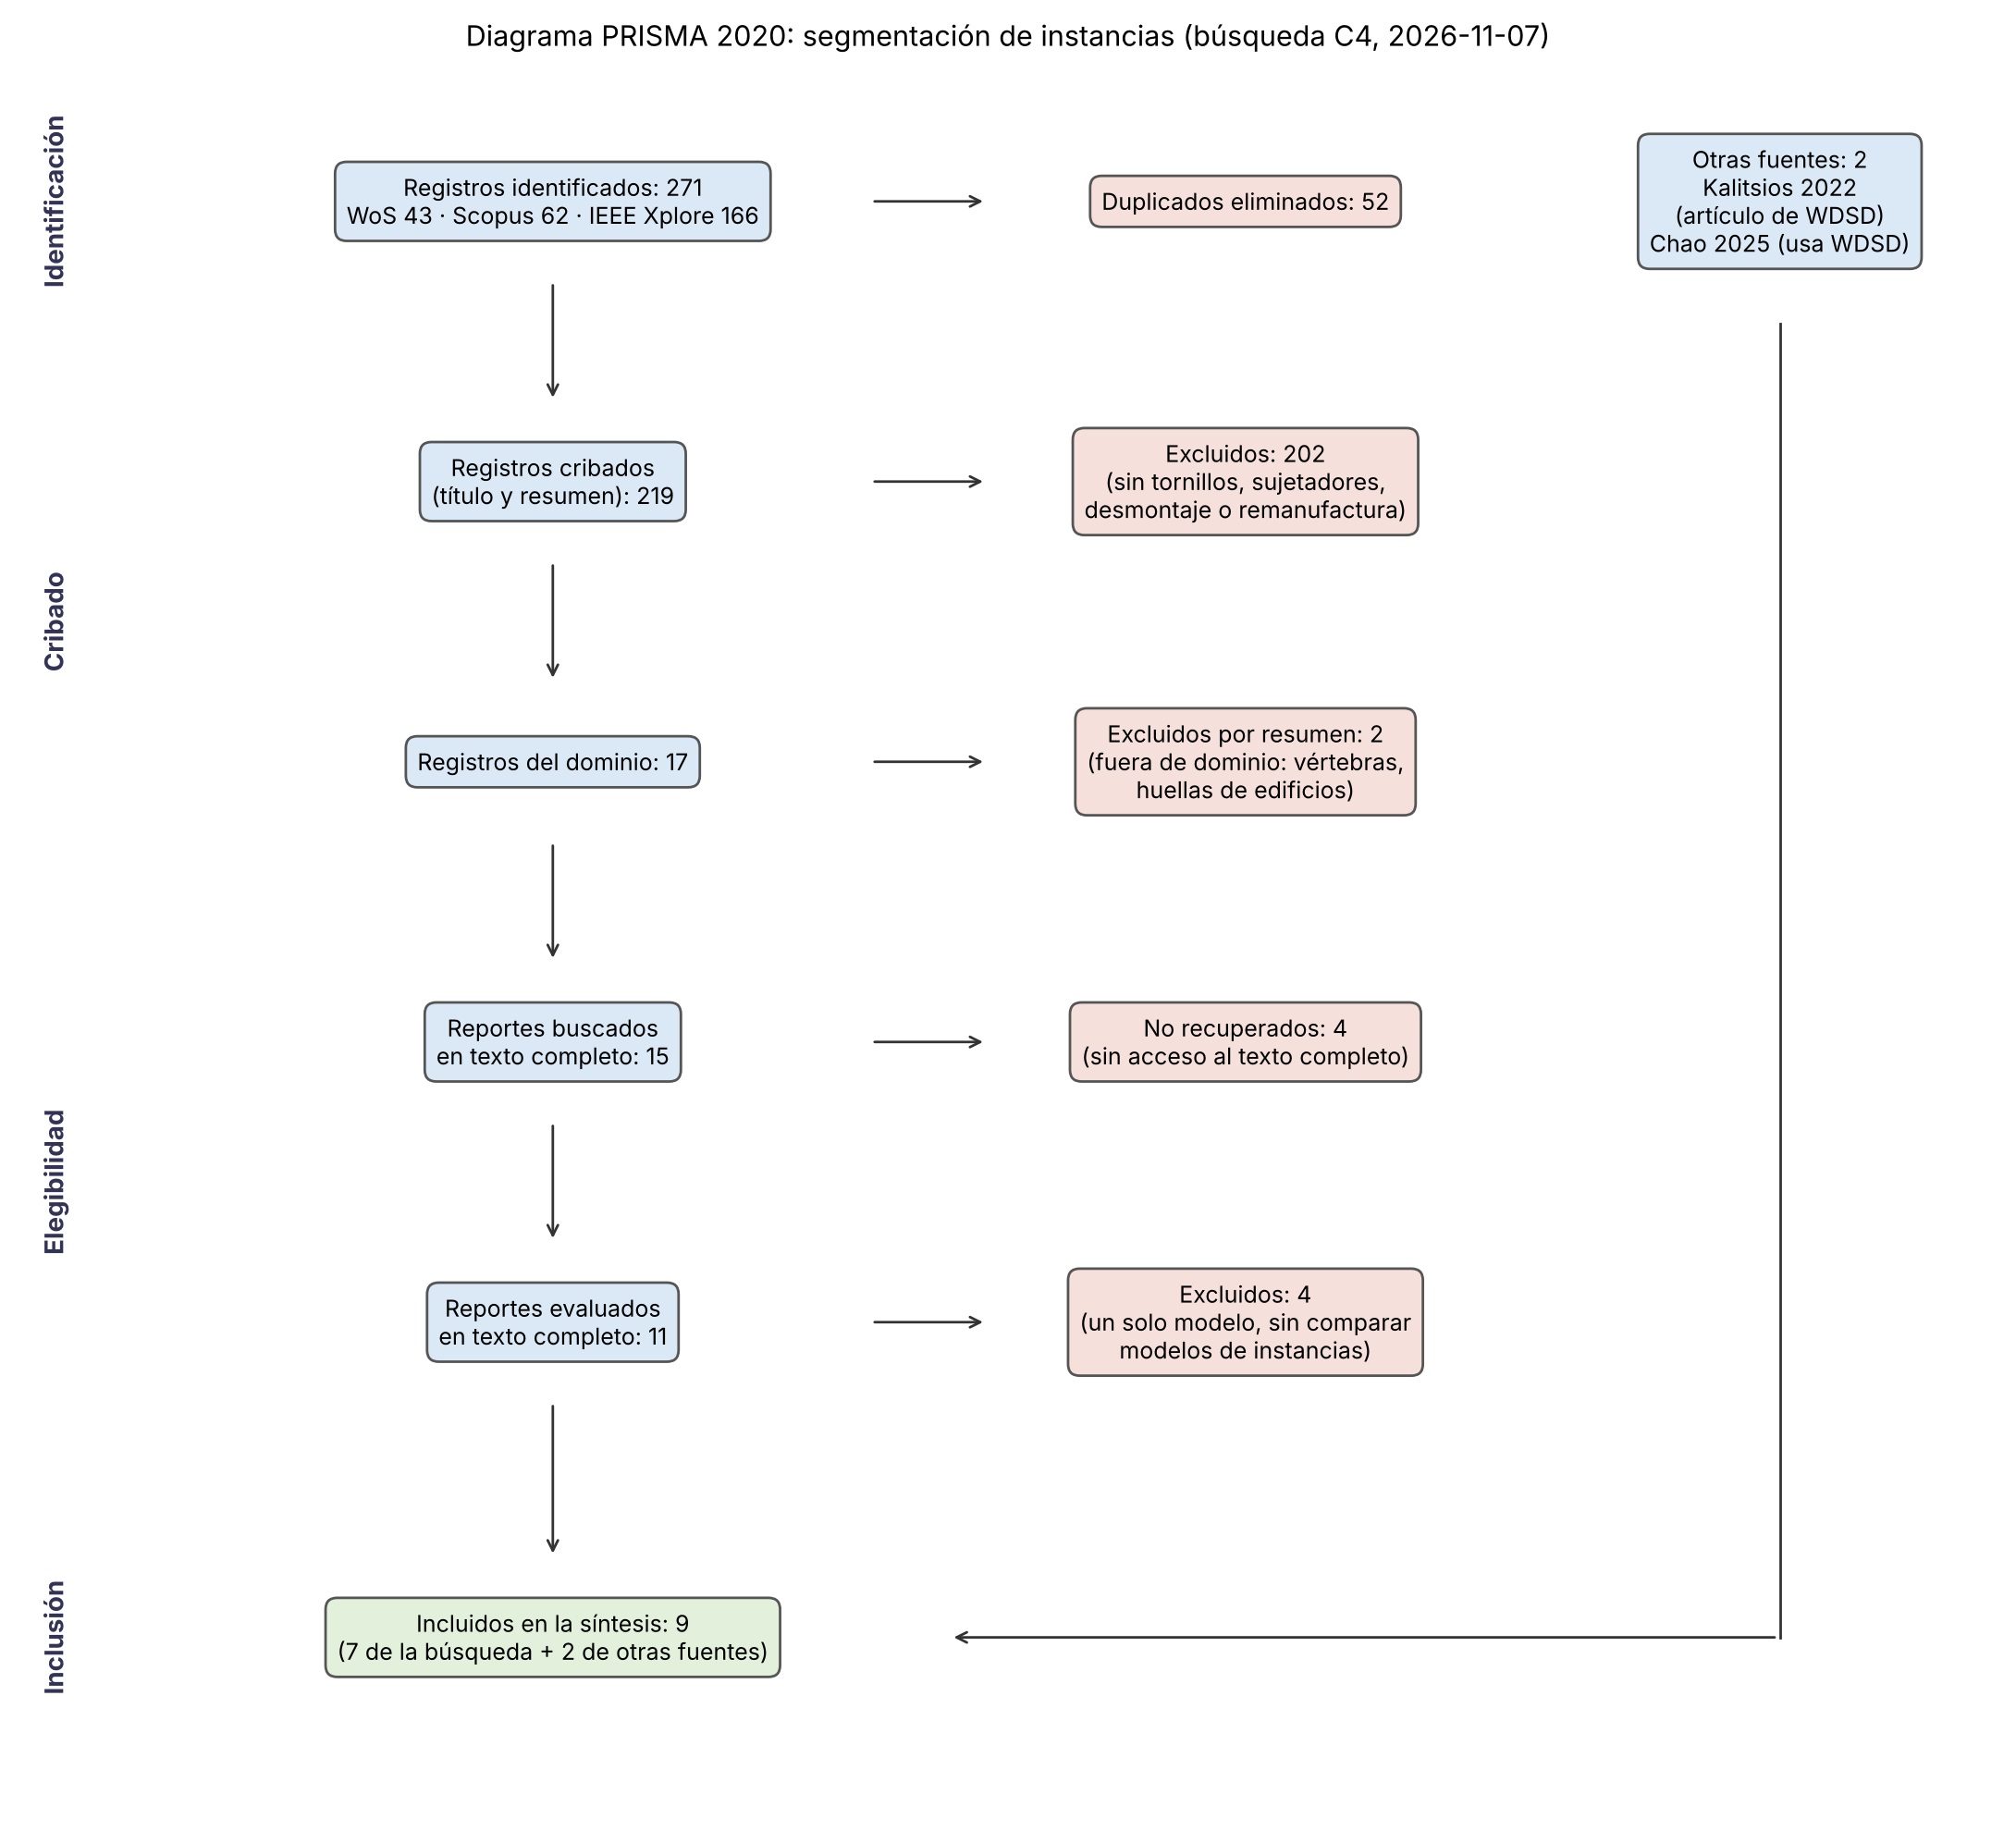

In [ ]:
Image(filename=str(LIT / 'prisma_instancias.png'), width=700)

### 3.2 Selección de los modelos base y tabla de síntesis

**Criterios:**
1. Frecuencia como comparador en la literatura.
2. Complejidad distinta entre sí.
3. No redundancia: cada modelo obtiene las instancias de una forma distinta.
4. Viables en una GPU de 6 GB.

**Frecuencia:**

| Modelo | Resúmenes de la búsqueda (219) | Estudios de la síntesis (9) |
|---|---|---|
| YOLO (cualquier versión) | 64 | — |
| Mask R-CNN | 59 | 6 |
| YOLO-seg | 25 | 5 |
| SOLO / SOLOv2 | 10 | 2 |
| YOLACT | 7 | 3 |

**Terna elegida: Mask R-CNN, YOLOv8-seg y SOLOv2.** Cubre las tres familias:

| Modelo | Familia |
|---|---|
| Mask R-CNN | Dos etapas con cajas |
| YOLOv8-seg | Una etapa con cajas y prototipos |
| SOLOv2 | Una etapa sin cajas |

**Limitación declarada.** En texto completo YOLACT supera a SOLOv2 (3 estudios contra 2), pero en los resúmenes el orden se invierte (7 contra 10). Además, YOLACT comparte con YOLOv8-seg el mecanismo de prototipos, así que sería redundante.

**Equivalencia con la regresión logística.** Las tres cabezas de máscara terminan en una sigmoide por píxel sobre características aprendidas, es decir, en una regresión logística por píxel:
- Mask R-CNN y YOLOv8-seg la entrenan con entropía cruzada binaria, que es la verosimilitud de la regresión logística.
- SOLOv2 la entrena con pérdida Dice.

Por eso son la "línea base mínima razonable" del enunciado para este tipo de problema.

**Tabla 3.4.** Tabla de síntesis de los 9 estudios incluidos.

In [ ]:
tabla = pd.read_csv(LIT / 'tabla_sintesis_instancias.csv')
display(tabla[['id', 'referencia', 'problema', 'dataset', 'modelos_DL_de_referencia', 'metricas',
               'valores_modelos_base', 'particion', 'repeticiones', 'prueba_estadistica']])

,id,referencia,problema,dataset,modelos_DL_de_referencia,metricas,valores_modelos_base,particion,repeticiones,prueba_estadistica
0,I1,Chen W.-Y. et al. (2022). Real-Time Instance Segmentation of Metal Screw Defects Based...,Segmentación de instancias de defectos en cabezas de tornillo,Propio: 3200 imgs microscopio (2880 train / 320 val),YOLACT vs Mask R-CNN,AP caja y máscara (IoU 0.5–0.95),"YOLACT mAP máscara 41.37, caja 40.11; Mask R-CNN solo comparado por curvas de entrenam...",Aleatoria 90/10 tras aumentar datos (posible fuga),1 corrida,No
1,I2,Qi K. et al. (2022). Fastener counting method with an improved Blendmask. ASCC 2022.,Conteo de sujetadores por segmentación de instancias (densos/dispersos),"Propio: 413 imgs, 9589 instancias","Mask R-CNN, SOLO, BlendMask (+ propuesta)","Error de cantidad, distancia media al centro de gravedad",Denso error 0.3/0.5: Mask R-CNN 8.84/10.40 %; SOLO 2.21/7.54 %; BlendMask 1.95/5.46 %....,"Fija train/val (366/47), sin test",1 corrida,No
2,I3,Ma J. et al. (2023). LPHD: Line Perspective Hexagonal Screw Detection. CCC 2023.,Contorno de tornillos hexagonales para atornillado robótico,Propio: 1115 imgs (1015 train / 100 test),Mask R-CNN (control) vs YOLOv5 + geometría (LPHD),"IoU medio, recall, tiempo","Mask R-CNN IoU 92.9 %, recall 98 %, 0.141 s; LPHD IoU 91.4 %, recall 100 %, 0.057 s",Fija 1015/100,1 corrida,No
3,I4,Wang Y. et al. (2024). YOLOv8n-BAseg Instance Segmentation Network for Angle Tower Bol...,Segmentación de instancias de grupos de pernos y placas en torres,Propio: 1050 imgs (aumentadas desde 210 por clase),"YOLOv8n-seg, YOLOv8s-seg, Fast-SAM (+ propuesta)","mAP50, parámetros, ms/img",YOLOv8n-seg 94.9 % (3.26 M); YOLOv8s-seg 99.3 % (11.78 M); Fast-SAM sin mAP,7:1:2 tras aumentar datos (posible fuga),1 corrida,"No (dice ""significantly"")"
4,I5,AF-YOLO (2026). A High-Precision Aircraft Safety Wire Segmentation Network for Assembl...,Segmentación de instancias de alambres/fusibles de seguridad en ensamble aeronáutico (...,Propio,"Mask R-CNN, YOLACT, SOLOv2, YOLOv8-seg, BlendMask (+ propuesta)","mAP, AP50, AP75, AR",mAP: Mask R-CNN 83.2; YOLACT 84.7; SOLOv2 86.1; YOLOv8-seg 87.3; BlendMask 89.6,Aleatoria 7:2:1,1 corrida,"No (dice ""significantly"")"
5,I6,Engineering Applications of AI 133 (2024) 108318. Instance segmentation algorithm for ...,Segmentación de instancias de piezas desmontadas de vehículos fuera de uso,Propio: 385 imgs originales → 4235 aumentadas,"Mask R-CNN, YOLACT, YOLOv5s-seg (+ SPGNet)","mAP@0.5 y 0.5:0.95 caja/máscara, GFLOPs, ms",mAP@0.5 máscara: Mask R-CNN 78.3; YOLACT 90.5; YOLOv5s-seg 90.1,7:3 train/val,1 corrida,No
6,I7,Footwear Damage Assessment for Remanufacturing: A Multi-View RGB Dataset and Instance ...,Segmentación de instancias de daños en calzado para remanufactura,Propio: 3858 imgs multivista,"YOLOv8s-seg, YOLOv11n-seg, Roboflow 3.0, RF-DETR","mAP@50, P, R, F1",mAP@50 global: YOLOv8s-seg 0.284; YOLOv11n-seg 0.308; Roboflow3 0.345; RF-DETR 0.339,80/10/10 agrupada por zapato (sin fuga),1 corrida,No
7,WDSD-1,Kalitsios G. et al. (2022). Vision-Enhanced System for Human-Robot Disassembly Factory...,Segmentación de instancias de tornillos en desmontaje de RAEE,WDSD (nuestro dataset),Mask R-CNN,AP COCO,Ver tabla anterior (sintesis/tabla_sintesis.csv),Oficial 765/90/90 (fuga por casi-duplicados),1 corrida,No
8,WDSD-2,Chao et al. (2025). Digital Twin.,Segmentación de instancias de tornillos y agujeros,387 imgs WDSD + propias,YOLOv8-seg (variante SM-Seg),mAP,Ver tabla anterior,Aleatoria tras aumentar datos,1 corrida,No


### 3.3 Modelos base

| Modelo | Artículo original | DOI o referencia |
|---|---|---|
| Mask R-CNN | He, Gkioxari, Dollár y Girshick (2017), ICCV, pp. 2980–2988 | 10.1109/ICCV.2017.322. Versión TPAMI 42(2):386–397, 2020: 10.1109/TPAMI.2018.2844175 |
| YOLOv8-seg | Jocher, Chaurasia y Qiu (2023), *Ultralytics YOLOv8*, versión 8.0.0, licencia AGPL-3.0 | No tiene artículo ni DOI; se cita como software: https://github.com/ultralytics/ultralytics. Mecanismo de prototipos: YOLACT, Bolya et al. (2019), ICCV, 10.1109/ICCV.2019.00925 |
| SOLOv2 | Wang, Zhang, Kong, Li y Shen (2020), NeurIPS 33 | arXiv 2003.10152, 10.48550/arXiv.2003.10152. Las páginas del volumen no se verificaron. Base SOLO: Wang et al. (2020), ECCV, pp. 649–665, 10.1007/978-3-030-58523-5_38 |

#### Mask R-CNN: dos etapas, con cajas

1. Una red de propuestas (RPN) sugiere regiones sobre un pirámide de características (ResNet-50-FPN).
2. RoIAlign recorta las características de cada región con interpolación bilineal, sin redondear coordenadas.
3. Tres cabezas en paralelo predicen clase, caja y una máscara de $m\times m$. En torchvision, $m=28$: RoIAlign de 14×14 seguido de una convolución transpuesta ×2.

**Pérdida por región**:

$$L = L_{cls} + L_{box} + L_{mask}, \qquad L_{mask} = -\frac{1}{m^2}\sum_{i,j}\big[y_{ij}\log\sigma(z_{ij}) + (1-y_{ij})\log(1-\sigma(z_{ij}))\big]$$

- $L_{mask}$ se calcula solo sobre el canal de la clase verdadera.
- torchvision suma además las dos pérdidas de la RPN (objetividad y regresión de la caja).

#### YOLOv8-seg: una etapa, con cajas y prototipos

En una sola pasada, la cabeza predice para cada posición:
- la caja;
- la clase;
- $k=32$ coeficientes de máscara.

En paralelo, una rama *Proto* genera 32 máscaras prototipo $P_k$ a 1/4 de la resolución de entrada. Toma P3 (paso 8) y lo sobremuestrea ×2.

**Máscara de una detección:**

$$\hat m = \sigma\Big(\sum_{k=1}^{32} c_k P_k\Big)$$

recortada a su caja.

**Pérdida**:

$$L = 7.5\,L_{CIoU} + 7.5\,L_{seg} + 0.5\,L_{cls} + 1.5\,L_{DFL}$$

- $L_{seg}$ es entropía cruzada binaria por píxel, recortada a la caja y normalizada por su área.
- $L_{cls}$ es entropía cruzada binaria.
- $L_{DFL}$ es la *distribution focal loss* de la caja.

#### SOLOv2: una etapa, sin cajas

1. La imagen se divide en una rejilla de $S\times S$ por nivel de la pirámide ($S$ = 40, 36, 24, 16, 12).
2. La celda que contiene el centro de un objeto es la responsable de ese objeto.
3. La rama de categoría predice un mapa $S\times S\times C$.
4. La rama de *kernel* predice, para cada celda, un filtro $G_{ij}$.
5. La máscara sale de una convolución dinámica, $M_{ij} = G_{ij} * F$, donde $F$ es una característica de máscara unificada a 1/4 de escala.
6. Las máscaras duplicadas se suprimen con Matrix NMS, que decae los scores en forma matricial con $f(\mathrm{iou}) = \exp(-\mathrm{iou}^2/\sigma)$.

**Pérdida**:

$$L = L_{cate} + \lambda L_{mask},\quad \lambda = 3,\qquad L_{mask} = \frac{1}{N_{pos}}\sum_k \mathbb{1}\{p^*_{k} > 0\}\,\big(1 - D(p_k, q_k)\big),\qquad D(p,q) = \frac{2\sum p_{xy}q_{xy}}{\sum p_{xy}^2 + \sum q_{xy}^2}$$

$L_{cate}$ es una *focal loss* con $\gamma = 2$ y $\alpha = 0.25$.

#### Parámetros y costo

Conteo hecho con el código del proyecto, con 1 clase:

| Modelo | Parámetros | Referencia publicada |
|---|---|---|
| Mask R-CNN R50-FPN (torchvision 0.29) | 43 922 395 | Con 91 clases da 44 401 393, igual a la documentación de torchvision (134.4 GFLOPs a 800 px) |
| YOLOv8n-seg (ultralytics 8.4.207) | 3 263 811 | 11.3 GFLOPs a 640 px, fusionado |
| SOLOv2 R50-FPN (MMDetection 3.3) | 46 228 801 | Comparte con Mask R-CNN el mismo ResNet-50-FPN (26.8 M parámetros) |

**Complejidad**. Para una imagen de $H\times W$:
- Cada convolución $k\times k$ de $C_{in}$ a $C_{out}$ cuesta $O(HW\,k^2C_{in}C_{out})$ en su resolución. Con la pirámide, el costo del extractor es $O(HW)$, con constantes distintas por modelo.
- **Mask R-CNN** suma un término por región: $O(HW + R\,m^2)$, con $R$ propuestas (512 por imagen en entrenamiento, hasta 1000 en inferencia).
- **YOLOv8-seg**: $O(HW + N\,k\,\tfrac{HW}{16})$ para ensamblar $N$ máscaras desde $k=32$ prototipos.
- **SOLOv2**: $O(HW + N\,E\,\tfrac{HW}{16})$ para la convolución dinámica de $N$ candidatos, más $O(N^2)$ en Matrix NMS.
- Las tres son lineales en el número de píxeles. Difieren en la constante y en cómo crecen con el número de instancias. El tiempo medido por corrida está en la sección 4.

### 3.4 Comparación crítica y vacío

Lectura completa en `lectura_critica_instancias.md`. Resumen:

- **No hay un orden estable entre los modelos.** En el único estudio con los tres modelos (AF-YOLO, objetos menores al 1 % de la imagen), el mAP de máscara queda en 83.2 (Mask R-CNN), 86.1 (SOLOv2) y 87.3 (YOLOv8-seg). En otro dominio, Mask R-CNN queda 12 puntos por debajo de los modelos de una etapa (SPGNet), y en conteo de sujetadores el orden cambia según la métrica.
- **Calidad metodológica de los 9 estudios:**
  - 0 usan más de una corrida;
  - 0 hacen prueba estadística;
  - 1 usa partición agrupada;
  - 3 aumentan datos antes de partir.
- **Los dos trabajos sobre WDSD:**
  - Kalitsios 2022: solo Mask R-CNN, partición oficial con fuga, AP 0.586.
  - Chao 2025: YOLOv8-seg, partición aleatoria tras aumentar datos.
- **Vacío:** ningún estudio compara Mask R-CNN, YOLOv8-seg y SOLOv2 en segmentación de instancias de tornillos con partición agrupada, varias semillas e inferencia estadística. Este trabajo cubre ese vacío.

## 4. Implementación de los modelos base

### 4.1 Protocolo experimental

Se entrenaron los tres modelos base (Mask R-CNN, YOLOv8-seg y SOLOv2) con cinco semillas cada uno (42 a 46): 15 corridas en total. Todas las corridas comparten el mismo protocolo:

- **Partición.** La partición agrupada congelada del EDA (`results/eda/particion.csv`): 744 imágenes de entrenamiento, 93 de validación y 108 de prueba. En prueba hay 14 grupos (sesiones o escenas de captura). Ninguna sesión aparece en más de un conjunto.
- **Entrada.** Imagen completa de 1280×720, sin reescalar ni recortar, porque el diámetro mediano de un tornillo es de 10.6 px (sección 2.5). Mask R-CNN y SOLOv2 usan solo volteo horizontal. YOLOv8-seg usa los aumentos por defecto de ultralytics: mosaico (apagado en las últimas 10 épocas), variación de color HSV, traslación de ±10 %, escala de ±50 % y volteo horizontal.
- **Inicialización.** Pesos preentrenados en COCO para los tres modelos.
- **Selección del modelo.** Se guarda la mejor época según el conjunto de validación: AP de máscara en Mask R-CNN y SOLOv2, y el *fitness* de ultralytics en YOLOv8-seg. El conjunto de prueba se evalúa una sola vez por corrida.
- **Umbral de confianza.** Las métricas por instancia (F1 y PQ) necesitan un umbral sobre el puntaje de cada detección. Se elige en validación, como el que maximiza el F1 medio por imagen, y se aplica sin cambios en prueba. El AP no usa umbral.

Tabla 4.1. Configuración por modelo.

| Modelo | Tipo | Parámetros | Épocas | Lote | Optimizador | Marco |
|---|---|---|---|---|---|---|
| Mask R-CNN (ResNet-50-FPN) | Dos etapas, con cajas | 43 922 395 | 12 | 2 | SGD, momento 0.9, calentamiento + coseno, lr 0.0025 × lote | torchvision 0.26 |
| YOLOv8n-seg | Una etapa, con cajas | 3 263 811 | 40 | 4 | Valores por defecto de ultralytics | ultralytics 8.4.207 |
| SOLOv2 (ResNet-50-FPN) | Una etapa, sin cajas | 46 228 801 | 12 | 2 | SGD, lr 0.01 × lote/16 (receta oficial `solov2_r50_fpn_1x_coco`) | MMDetection 3.3 |

Mask R-CNN usa anclas de 8 a 128 px en lugar de las de 32 a 512 px que trae torchvision por defecto, porque el 98,8 % de los tornillos son *small* según COCO (menos de 32×32 px) (sección 2.5).

**Hardware y reparto.** Las corridas se repartieron entre dos máquinas por semilla, no por modelo:
- semillas 42, 43 y 44 en una RTX 3060 Laptop de 6 GB;
- semillas 45 y 46 en una RTX 3050 Laptop de 6 GB.

Las dos usaron la misma configuración y las mismas versiones de los paquetes (`requirements_wdsd_dl_congelado.txt`). Así, cualquier efecto de la máquina cae por igual sobre los tres modelos.

### 4.2 Corridas

Cada corrida deja en `results/instancias/corridas/<modelo>_s<semilla>/`:
- `resumen.json`: entorno, tiempo, memoria y métricas;
- `metricas.json`: AP, F1 y PQ en validación y prueba, y el umbral elegido en validación;
- `test_por_imagen.csv`: una fila por imagen de prueba (TP, FP, FN, F1, PQ), entrada de la sección 5;
- `preds_val.json` y `preds_test.json`: predicciones en formato COCO, para recalcular cualquier métrica sin reentrenar.

**Tabla 4.2.** Las 15 corridas.

In [ ]:
filas = []
for d in sorted(CORR.glob('*_s*')):
    if not (d / 'resumen.json').exists():
        continue
    r = json.loads((d / 'resumen.json').read_text(encoding='utf8'))
    m = r['metricas']
    filas.append({'modelo': MODELOS[r['modelo']], 'semilla': r['semilla'], 'GPU': r['entorno']['gpu'].replace('NVIDIA GeForce ', ''),
                  'épocas': r['epocas'], 'min': round(r['s_total'] / 60, 1), 'umbral (val)': m['umbral_score'],
                  'val AP': round(m['val']['AP'], 3), 'test F1 img': round(m['test']['F1_img'], 3),
                  'test AP': round(m['test']['AP'], 3)})
corridas = pd.DataFrame(filas)
display(corridas)

,modelo,semilla,GPU,épocas,min,umbral (val),val AP,test F1 img,test AP
0,Mask R-CNN,42,RTX 3060 Laptop GPU,12,33.7,0.70,0.294,0.458,0.214
1,Mask R-CNN,43,RTX 3060 Laptop GPU,12,33.0,0.50,0.284,0.447,0.217
2,Mask R-CNN,44,RTX 3060 Laptop GPU,12,33.7,0.60,0.289,0.418,0.217
3,Mask R-CNN,45,RTX 3050 6GB Laptop GPU,12,76.0,0.60,0.282,0.450,0.214
4,Mask R-CNN,46,RTX 3050 6GB Laptop GPU,12,70.9,0.60,0.288,0.461,0.223
5,SOLOv2,42,RTX 3060 Laptop GPU,12,32.6,0.25,0.124,0.326,0.104
6,SOLOv2,43,RTX 3060 Laptop GPU,12,31.3,0.20,0.133,0.310,0.117
7,SOLOv2,44,RTX 3060 Laptop GPU,12,31.3,0.15,0.132,0.256,0.116
8,SOLOv2,45,RTX 3050 6GB Laptop GPU,12,56.3,0.20,0.132,0.305,0.111
9,SOLOv2,46,RTX 3050 6GB Laptop GPU,12,55.5,0.20,0.131,0.287,0.116


### 4.3 Costo computacional

**Tabla 4.3.** Costo computacional por corrida (entrenamiento + evaluación).

| Modelo | Minutos, RTX 3060 (3 semillas) | Minutos, RTX 3050 (2 semillas) | Memoria GPU pico (GB) |
|---|---|---|---|
| Mask R-CNN | 33.5 | 73.5 | 2.7 |
| YOLOv8-seg | 21.0 | 62.4 | 2.6 |
| SOLOv2 | 31.7 | 55.9 | ~2.6* |

\* Para SOLOv2 se toma el pico del registro de MMDetection durante el entrenamiento; el contador de PyTorch del script se reinicia dentro de MMDetection y da un valor menor que no corresponde al entrenamiento.

In [ ]:
corridas.groupby(['modelo', 'GPU'])['min'].agg(['mean', 'count']).round(1)

mean  count
modelo     GPU                                 
Mask R-CNN RTX 3050 6GB Laptop GPU  73.4      2
           RTX 3060 Laptop GPU      33.5      3
SOLOv2     RTX 3050 6GB Laptop GPU  55.9      2
           RTX 3060 Laptop GPU      31.7      3
YOLOv8-seg RTX 3050 6GB Laptop GPU  62.4      2
           RTX 3060 Laptop GPU      21.0      3

### 4.4 Curvas de entrenamiento y validación

**Figura 4.1.** Pérdida de entrenamiento (arriba) y AP de máscara en validación (abajo) por época, una línea por semilla. Cada marco reporta su propia pérdida total, así que las escalas no se comparan entre modelos. El AP de YOLOv8-seg es el que calcula ultralytics; el de Mask R-CNN y SOLOv2 sale de COCOeval. En las tres columnas se guarda la época con mejor AP de validación.

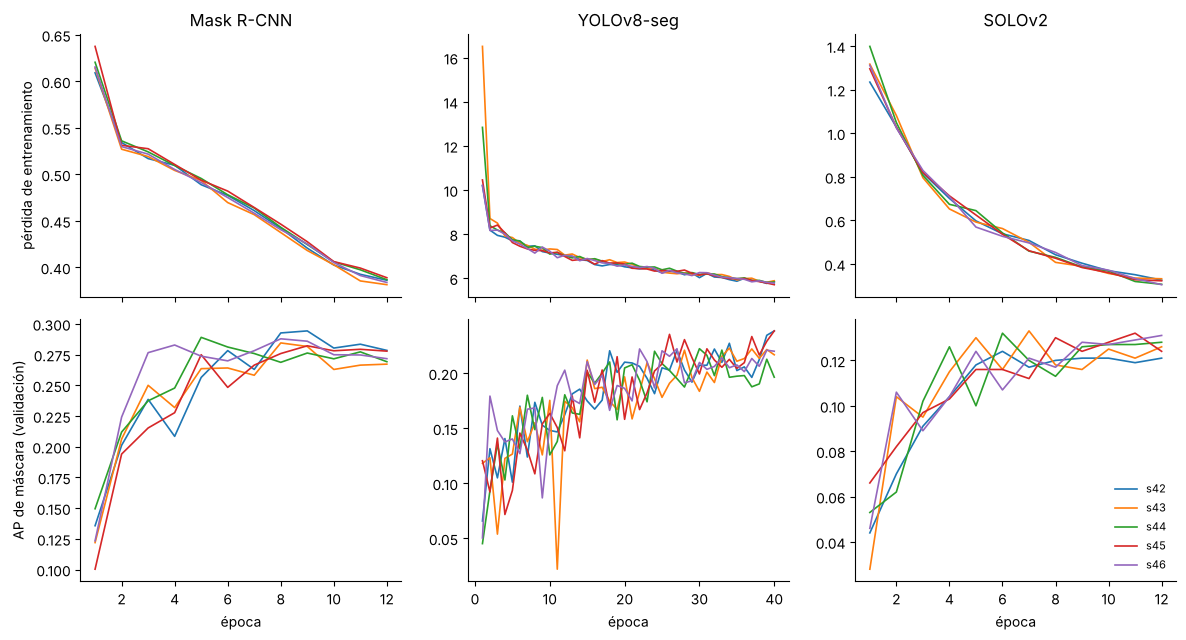

In [ ]:
def curvas(d, m):
    if m == 'maskrcnn':
        h = pd.read_csv(d / 'historial.csv')
        return h.epoca, h.perdida, h.epoca, h.val_AP
    if m == 'yolov8seg':
        h = pd.read_csv(d / 'ultra' / 'results.csv'); h.columns = h.columns.str.strip()
        perd = h[['train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss']].sum(axis=1)
        return h.epoch, perd, h.epoch, h['metrics/mAP50-95(M)']
    escal = max(d.glob('*/vis_data/scalars.json'), key=lambda p: p.stat().st_size)
    filas = [json.loads(l) for l in escal.read_text(encoding='utf8').splitlines() if l.strip()]
    tr = pd.DataFrame([f for f in filas if 'loss' in f]).groupby('epoch').loss.mean()
    va = pd.DataFrame([f for f in filas if 'coco/segm_mAP' in f])
    return tr.index, tr.values, va.step, va['coco/segm_mAP']

orden = ['maskrcnn', 'yolov8seg', 'solov2']
fig, ax = plt.subplots(2, 3, figsize=(12, 6.5), sharex='col')
for j, m in enumerate(orden):
    for d in sorted(CORR.glob(f'{m}_s*')):
        e1, perd, e2, ap = curvas(d, m)
        s = d.name.rsplit('_s', 1)[1]
        ax[0, j].plot(e1, perd, lw=1.2, label=f's{s}')
        ax[1, j].plot(e2, ap, lw=1.2, label=f's{s}')
    ax[0, j].set_title(MODELOS[m]); ax[1, j].set_xlabel('época')
    for a in ax[:, j]:
        a.spines[['top', 'right']].set_visible(False)
ax[0, 0].set_ylabel('pérdida de entrenamiento'); ax[1, 0].set_ylabel('AP de máscara (validación)')
ax[1, 2].legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

**Lectura (observada en la figura).**
- **Pérdida de entrenamiento.** Baja de forma monótona en los tres modelos, y las 5 semillas siguen trayectorias casi idénticas.
- **Mask R-CNN.** El AP de validación sube hasta las épocas 8 y 9 (≈ 0.29) y después se aplana o cae un poco (≈ 0.27), mientras la pérdida sigue bajando: es un sobreajuste leve al final. La selección por validación se queda con la mejor época.
- **YOLOv8-seg.** El AP de validación sigue subiendo en la época 40 y oscila bastante de una época a otra. Con más épocas probablemente mejoraría, así que el presupuesto fijo lo deja en desventaja (ver limitaciones).
- **SOLOv2.** Llega a ≈ 0.12 hacia la época 5 y después se queda entre 0.11 y 0.13. Más épocas no parecen capaces de cerrar la distancia con los otros dos.

No hay métricas en el conjunto de entrenamiento, así que la brecha entre entrenamiento y validación se juzga por la forma de las curvas, no con un número.

### 4.5 Estudio piloto y dimensionamiento (a posteriori)

El enunciado pide un estudio piloto con al menos 5 semillas por modelo sobre validación, previo a la ejecución definitiva. **No se hizo antes.** Por el calendario, las 5 semillas definitivas se lanzaron directamente. Se reporta aquí el mismo cálculo hecho con esas 5 semillas, sobre validación, como dimensionamiento a posteriori y como punto de partida para el número de semillas del E2. Las corridas se emparejan por semilla, como pide el enunciado.

**Tabla 4.4.** F1 de instancia por imagen en validación: media, desviación estándar y coeficiente de variación sobre las 5 semillas.

In [ ]:
from itertools import combinations
DELTA = 0.03
filas = []
for d in sorted(CORR.glob('*_s*')):
    mod, s = d.name.rsplit('_s', 1)
    m = json.loads((d / 'metricas.json').read_text(encoding='utf8'))
    filas.append({'modelo': mod, 'semilla': int(s), 'F1_val': m['val']['F1_img']})
val = pd.DataFrame(filas).pivot(index='semilla', columns='modelo', values='F1_val')[orden]
piloto = val.agg(['mean', 'std']).T.rename(columns={'mean': 'media', 'std': 'DE'})
piloto['CV (%)'] = 100 * piloto['DE'] / piloto['media']
display(piloto.rename(index=MODELOS).round(4))

,media,DE,CV (%)
modelo,,,
Mask R-CNN,0.6584,0.0224,3.3993
YOLOv8-seg,0.6842,0.0356,5.1956
SOLOv2,0.4019,0.0106,2.6463


**Tabla 4.5.** Dimensionamiento por par: $\hat\sigma_d$ es la desviación estándar de las diferencias pareadas por semilla; $R \approx (z_{0.975} + z_{0.80})^2\, \hat\sigma_d^2 / \delta^2$ es el número de corridas necesario para detectar δ = 0.03 con potencia 0.80 y α = 0.05; el MDE es la menor diferencia detectable con las 5 corridas hechas.

In [ ]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
filas = []
for a, b in combinations(orden, 2):
    dif = val[a] - val[b]; sd = dif.std(ddof=1)
    filas.append({'par': f'{MODELOS[a]} − {MODELOS[b]}', 'dif. media (val)': dif.mean(), 'σd': sd,
                  'δ/σd': DELTA / sd, 'R necesarias': int(np.ceil(z**2 * sd**2 / DELTA**2)),
                  'MDE con 5 corridas': z * sd / np.sqrt(len(dif)), 'Shapiro–Wilk p': stats.shapiro(dif).pvalue})
display(pd.DataFrame(filas).round(4))

,par,dif. media (val),σd,δ/σd,R necesarias,MDE con 5 corridas,Shapiro–Wilk p
0,Mask R-CNN − YOLOv8-seg,-0.0259,0.0260,1.1519,6,0.0326,0.4090
1,Mask R-CNN − SOLOv2,0.2564,0.0181,1.6589,3,0.0227,0.3702
2,YOLOv8-seg − SOLOv2,0.2823,0.0282,1.0650,7,0.0353,0.1479


**Lectura.**
- La variabilidad entre semillas es baja: CV de 2.6 % a 5.2 %, mayor en YOLOv8-seg.
- Para detectar δ = 0.03 entre corridas harían falta de 3 a 7 corridas según el par. Con las 5 hechas, el MDE entre corridas queda entre 0.023 y 0.035, cerca de δ.
- Shapiro–Wilk no rechaza la normalidad de las diferencias (p ≥ 0.15). Con solo 5 valores, esa prueba tiene muy poca potencia.

**El cuello de botella no son las semillas, sino los grupos de prueba.** La sección 5 compara por grupo (n = 14), porque las imágenes de un grupo no son independientes. Ahí el MDE de Mask R-CNN frente a YOLOv8-seg es 0.10, tres veces δ. Agregar semillas apenas lo cambia, porque la variación que domina es la de un grupo a otro. Para el E2 conviene más ampliar la prueba con más grupos que agregar semillas, y por eso se mantiene δ = 0.03 como margen práctico.

## 5. Línea base estadística

### 5.1 Métricas

- **Primaria, declarada a priori: F1 de instancia por imagen.** En cada imagen se emparejan predicciones y tornillos reales con el algoritmo húngaro. Una pareja cuenta como acierto (TP) si su IoU de máscara es de al menos 0.5. Con eso, F1 = 2·TP / (2·TP + FP + FN). FP son las predicciones sin pareja y FN los tornillos sin detectar.
- **Secundarias:**
  - PQ (*panoptic quality*) = SQ × F1, donde SQ es el IoU medio de los aciertos;
  - AP50 de máscara.
- **Informativa:** AP de máscara promediado en IoU de 0.5 a 0.95, el estándar de COCO.
- **Umbral práctico:** δ = 0.03 en F1, declarado a priori en el EDA.

### 5.2 Resultados por modelo

**Tabla 5.1.** Desempeño en prueba: media, desviación estándar e intervalo de confianza del 95 % (t de Student) sobre las 5 semillas.

In [ ]:
res = EI.analizar(CORR)  # imprime también el detalle; se resume abajo

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== f1 por grupo (n = 14 grupos)
 modelo  m

In [ ]:
_, runs = EI.cargar(CORR)
def ic(x):
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f'{x.mean():.3f} ± {x.std(ddof=1):.3f} [{x.mean() - h:.3f}, {x.mean() + h:.3f}]'
tabla51 = runs.groupby('modelo').agg(n=('semilla', 'nunique'), F1_img=('F1_img', ic), PQ_img=('PQ_img', ic),
                                      AP50=('AP50', ic), AP=('AP', ic)).rename(index=MODELOS)
display(tabla51)

,n,F1_img,PQ_img,AP50,AP
modelo,,,,,
Mask R-CNN,5,"0.447 ± 0.017 [0.425, 0.468]","0.313 ± 0.011 [0.300, 0.327]","0.587 ± 0.010 [0.575, 0.599]","0.217 ± 0.004 [0.212, 0.222]"
SOLOv2,5,"0.297 ± 0.027 [0.263, 0.330]","0.210 ± 0.017 [0.189, 0.231]","0.285 ± 0.017 [0.264, 0.306]","0.113 ± 0.005 [0.106, 0.119]"
YOLOv8-seg,5,"0.521 ± 0.061 [0.445, 0.597]","0.365 ± 0.040 [0.316, 0.415]","0.637 ± 0.019 [0.614, 0.661]","0.234 ± 0.008 [0.224, 0.245]"


**Tabla 5.2.** Conteos agregados en prueba (5 semillas × 108 imágenes): de dónde sale cada F1.

In [ ]:
imgs, _ = EI.cargar(CORR)
cont = imgs.groupby('modelo')[['tp', 'fp', 'fn', 'n_gt', 'n_pred']].sum()
cont['precisión'] = (cont.tp / cont.n_pred).round(3)
cont['recall'] = (cont.tp / cont.n_gt).round(3)
display(cont.rename(index=MODELOS))

,tp,fp,fn,n_gt,n_pred,precisión,recall
modelo,,,,,,,
Mask R-CNN,1132,742,813,1945,1874,0.604,0.582
SOLOv2,595,410,1350,1945,1005,0.592,0.306
YOLOv8-seg,1220,706,725,1945,1926,0.633,0.627


### 5.3 Comparación estadística

**Unidad de análisis.** La unidad de independencia es el grupo, no la imagen, porque las imágenes de una misma sesión están correlacionadas. Para cada modelo y grupo de prueba se promedia el F1 de las imágenes del grupo y luego el de las semillas. Resulta una tabla de 14 grupos × 3 modelos.

**Pruebas.**
1. **Friedman** sobre los tres modelos, con los grupos como bloques. Prueba si al menos un modelo difiere de los otros.
2. **Wilcoxon pareado por grupo** para cada par de modelos, con corrección de Holm por los 3 contrastes.
3. **Intervalo bootstrap del 95 %** de la diferencia media por par, remuestreando grupos (10 000 réplicas).
4. **Efecto mínimo detectable (MDE)** de cada par, con el alfa de Holm y potencia 0.80. Si el MDE es mayor que δ, la prueba no tiene potencia para detectar una diferencia práctica, y un resultado no significativo se reporta como no concluyente, no como empate.

**Tabla 5.3.** F1 medio por grupo de prueba (promedio de las imágenes del grupo y luego de las 5 semillas).

In [ ]:
g = res['por_grupo'].rename(columns=MODELOS)
n_img = imgs.drop_duplicates('archivo').groupby('grupo').size().rename('imágenes')
display(g.join(n_img).round(3))
print(f"Friedman: chi2 = {res['friedman']['estadistico']:.2f}, p = {res['friedman']['p']:.4f}")

,Mask R-CNN,SOLOv2,YOLOv8-seg,imágenes
grupo,,,,
6,0.291,0.000,0.239,15
9,0.018,0.000,0.224,28
12,0.681,0.648,0.665,15
27,0.725,0.733,0.760,13
32,0.560,0.328,0.823,16
45,0.764,0.000,0.705,1
58,0.941,0.105,0.933,1
69,0.948,0.715,0.918,1
77,0.882,0.164,0.764,1


Friedman: chi2 = 16.62, p = 0.0002


**Figura 5.1.** F1 por grupo de prueba. Cada línea une los tres modelos en un mismo grupo; el tamaño del punto es proporcional al número de imágenes del grupo.

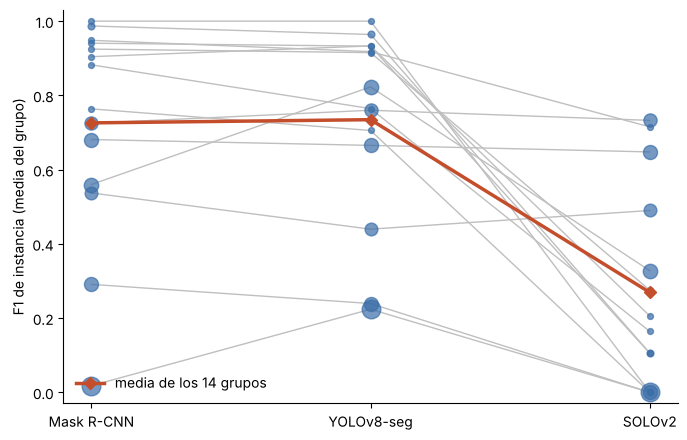

In [ ]:
orden = ['maskrcnn', 'yolov8seg', 'solov2']
gg = res['por_grupo'][orden]
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(orden))
for grupo, fila in gg.iterrows():
    ax.plot(x, fila.values, color='0.75', lw=1, zorder=1)
    ax.scatter(x, fila.values, s=12 + 6 * n_img[grupo], color='#3b6ea8', alpha=0.7, zorder=2)
ax.plot(x, gg.mean().values, color='#c44e2b', lw=2.5, marker='D', label='media de los 14 grupos', zorder=3)
ax.set_xticks(x, [MODELOS[m] for m in orden])
ax.set_ylabel('F1 de instancia (media del grupo)')
ax.set_ylim(-0.03, 1.03)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.show()

**Tabla 5.4.** Contrastes por pares (unidad = grupo, n = 14; Wilcoxon pareado con corrección de Holm, IC95 bootstrap remuestreando grupos, MDE con potencia 0.80).

In [ ]:
pares = res['pares'].copy()
for k, v in MODELOS.items():
    pares['par'] = pares['par'].str.replace(k, v)
display(pares.round(4))

,par,dif_media,de_dif,ic95_boot_grupos,wilcoxon_W,p,gana_a_en_grupos,p_holm,MDE,supera_delta
0,Mask R-CNN - SOLOv2,0.4567,0.3679,"(0.2683, 0.6393)",1.0,0.0002,13,0.0007,0.3556,True
1,Mask R-CNN - YOLOv8-seg,-0.0086,0.1052,"(-0.0655, 0.0389)",37.0,0.5525,9,0.5525,0.1017,False
2,SOLOv2 - YOLOv8-seg,-0.4653,0.3491,"(-0.6408, -0.2846)",3.0,0.0006,1,0.0012,0.3374,True


Con PQ como métrica secundaria:

In [ ]:
res_pq = EI.analizar(CORR, metrica='pq')

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== pq por grupo (n = 14 grupos)
 modelo  m

#### Supuestos, tamaño de efecto y diferencia relativa

**Tabla 5.5.** Por par y sobre los 14 grupos:
- Shapiro–Wilk de las diferencias pareadas;
- t pareado, como contraste paramétrico de referencia;
- d de Cohen pareada (media/DE de las diferencias);
- r biserial de rangos (el tamaño de efecto del Wilcoxon);
- probabilidad de superioridad (fracción de grupos donde gana el primero, con empates a la mitad);
- diferencia relativa respecto al segundo modelo del par.

In [ ]:
g = res['por_grupo']
filas = []
for a, b in combinations(sorted(g.columns), 2):
    dif = (g[a] - g[b]).to_numpy()
    nz = dif[dif != 0]; rk = stats.rankdata(np.abs(nz))
    wp, wm = rk[nz > 0].sum(), rk[nz < 0].sum()
    filas.append({'par': f'{MODELOS[a]} − {MODELOS[b]}', 'dif. media': dif.mean(),
                  'dif. relativa (%)': 100 * dif.mean() / g[b].mean(),
                  'Shapiro–Wilk p': stats.shapiro(dif).pvalue, 't pareado p': stats.ttest_rel(g[a], g[b]).pvalue,
                  'd de Cohen pareada': dif.mean() / dif.std(ddof=1), 'r biserial': (wp - wm) / (wp + wm),
                  'P(superioridad)': ((dif > 0).sum() + 0.5 * (dif == 0).sum()) / len(dif)})
efectos = pd.DataFrame(filas)
display(efectos.round(4))

,par,dif. media,dif. relativa (%),Shapiro–Wilk p,t pareado p,d de Cohen pareada,r biserial,P(superioridad)
0,Mask R-CNN − SOLOv2,0.4567,169.6418,0.0586,0.0005,1.2412,0.9810,0.9286
1,Mask R-CNN − YOLOv8-seg,-0.0086,-1.1762,0.0085,0.7635,-0.0821,0.1868,0.6786
2,SOLOv2 − YOLOv8-seg,-0.4653,-63.3500,0.2970,0.0002,-1.3331,-0.9429,0.0714


**Figura 5.2.** Gráficos Q–Q de las diferencias por grupo de cada par.

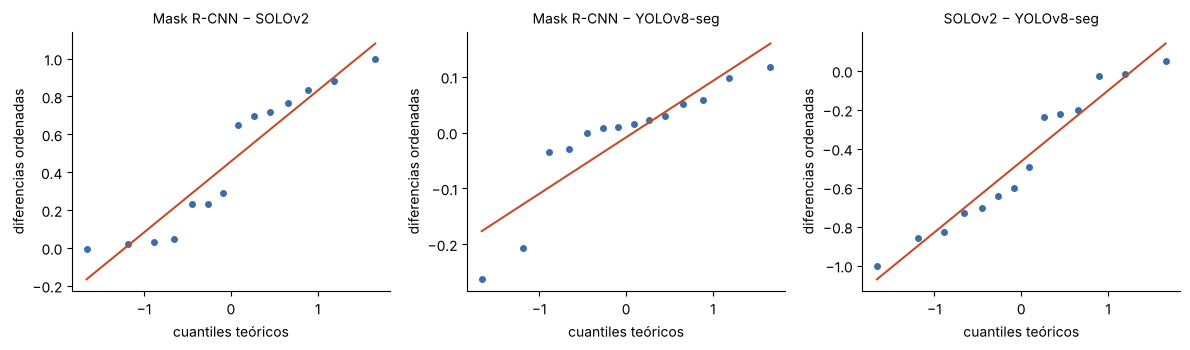

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for k, (a, b) in enumerate(combinations(sorted(g.columns), 2)):
    stats.probplot(g[a] - g[b], dist='norm', plot=ax[k])
    ax[k].set_title(f'{MODELOS[a]} − {MODELOS[b]}', fontsize=10)
    ax[k].get_lines()[0].set(markersize=4, color='#3b6ea8'); ax[k].get_lines()[1].set(color='#c44e2b')
    ax[k].set_xlabel('cuantiles teóricos'); ax[k].set_ylabel('diferencias ordenadas')
    ax[k].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Descomposición de la varianza.** Hay dos niveles:
- **Entre las 15 corridas:** qué parte de la varianza del F1 por imagen en prueba se debe al modelo y qué parte a la semilla.
- **En la tabla de 14 grupos × 3 modelos:** qué parte se debe al grupo (la escena), qué parte al modelo y qué parte a la interacción con el residuo.

In [ ]:
gm = runs.F1_img.mean()
ss_tot = ((runs.F1_img - gm) ** 2).sum()
ss_mod = runs.groupby('modelo').F1_img.apply(lambda v: len(v) * (v.mean() - gm) ** 2).sum()
print(f'Corridas: modelo {100 * ss_mod / ss_tot:.1f} %, semilla {100 * (1 - ss_mod / ss_tot):.1f} % de la suma de cuadrados')
G = g.to_numpy(); m0 = G.mean(); n_g, k_m = G.shape
ss_t = ((G - m0) ** 2).sum()
ss_g = k_m * ((G.mean(1) - m0) ** 2).sum(); ss_m = n_g * ((G.mean(0) - m0) ** 2).sum()
print(f'Grupos x modelos: grupo {100 * ss_g / ss_t:.1f} %, modelo {100 * ss_m / ss_t:.1f} %, '
      f'interacción y residuo {100 * (ss_t - ss_g - ss_m) / ss_t:.1f} %')

Corridas: modelo 87.2 %, semilla 12.8 % de la suma de cuadrados
Grupos x modelos: grupo 36.0 %, modelo 40.3 %, interacción y residuo 23.6 %


**Lectura de los supuestos y efectos.**
- **Mask R-CNN − YOLOv8-seg.** Shapiro–Wilk rechaza la normalidad (p = 0.009). En el Q–Q hay dos grupos donde YOLOv8-seg gana por mucho (diferencias de −0.21 y −0.26) y que se salen de la recta. Eso justifica usar Wilcoxon como prueba principal en vez de t pareado; el t pareado da la misma conclusión (p = 0.76).
- **Efecto pequeño y de signo ambiguo.** La d pareada es −0.08 (casi nula), pero el r biserial es +0.19 y la probabilidad de superioridad 0.68. Mask R-CNN gana en más grupos, pero por poco, mientras que YOLOv8-seg gana por más en los grupos donde gana. Las dos lecturas apuntan a lo mismo: ninguno domina.
- **Los contrastes con SOLOv2** tienen efectos grandes en cualquier escala: |d| ≥ 1.2, |r| ≥ 0.94, probabilidad de superioridad de 0.93 y 0.07. En diferencia relativa, SOLOv2 queda un 63 % por debajo de YOLOv8-seg en F1 por grupo.
- **Varianza entre corridas.** El modelo explica la mayor parte (≈ 87 %); la semilla aporta poco.
- **Varianza por grupo.** El grupo pesa casi tanto como el modelo (36 % frente a 40 %): la escena cambia el resultado tanto como cambiar de arquitectura. Es otra razón para usar el grupo como unidad de inferencia y para ampliar la prueba con más escenas en el E2.

No se afirma equivalencia entre Mask R-CNN y YOLOv8-seg. Para hacerlo haría falta un TOST con margen δ, y con un MDE de 0.10 no tendría potencia.

**Lectura.**
- **SOLOv2 queda por debajo de los otros dos** con una diferencia grande (≈0.46 en F1 por grupo), muy por encima de δ = 0.03 y significativa tras Holm. Pierde en 13 de los 14 grupos frente a cada uno de los otros modelos. La tabla 5.2 muestra de dónde viene: su precisión es similar a la de los otros (0.59 frente a 0.60–0.63), pero su recall es la mitad (0.31 frente a 0.58–0.63). Deja de detectar la mitad de los tornillos. Una explicación plausible, no verificada con un experimento, es su forma de asignar objetos: SOLOv2 decide la presencia de una instancia en una cuadrícula de 40 × 40 celdas, que a 1280 px son celdas de unos 32 px, mientras que el tornillo mediano mide 12 px.
- **Mask R-CNN y YOLOv8-seg no se distinguen con estos datos.** La diferencia por grupo es de −0.009 (IC95 [−0.066, 0.039]; p de Holm = 0.55). El efecto mínimo detectable con 14 grupos es de 0.102, mayor que δ = 0.03, así que el resultado es **no concluyente**: no se puede afirmar que sean equivalentes, solo que la prueba no tiene potencia para separarlos.
- **La media por imagen y la media por grupo cuentan historias distintas.** Por imagen, YOLOv8-seg supera a Mask R-CNN (0.52 frente a 0.45), pero buena parte de esa ventaja viene del grupo 9, que tiene 28 de las 108 imágenes de prueba: allí Mask R-CNN casi no acierta (F1 0.02) y YOLOv8-seg llega a 0.22. Al usar el grupo como unidad, ese grupo pesa lo mismo que los demás y la ventaja desaparece. Por eso la conclusión se apoya en el análisis por grupo.
- **El reparto entre máquinas no cambia el patrón.** Las semillas de la RTX 3050 (45 y 46) quedan en el mismo rango que las de la RTX 3060 en F1 por imagen: Mask R-CNN 0.450 y 0.461 frente a 0.418–0.458; YOLOv8-seg 0.568 y 0.504 frente a 0.429–0.584; SOLOv2 0.305 y 0.287 frente a 0.256–0.326. Lo que cambia es el tiempo de cómputo.

### 5.4 Baseline y margen de mejora

- **Baseline de referencia.** Por imagen, el mejor modelo base es **YOLOv8-seg**: F1 de instancia de 0.521 ± 0.061, IC95 [0.445, 0.597] con t de Student sobre 5 semillas. Por grupo no se distingue de Mask R-CNN (0.735 frente a 0.726). El baseline que hereda el E2 es, por lo tanto, el nivel de los dos mejores modelos base:
  - **F1 por imagen ≈ 0.52** (YOLOv8-seg);
  - **F1 por grupo ≈ 0.73**.

  Se toma YOLOv8-seg como modelo de referencia porque tiene el mejor F1 por imagen y la menor complejidad: 3.3 M parámetros frente a 44 M de Mask R-CNN, y el menor tiempo por corrida.
- **Umbral de mejora para un modelo avanzado.** Tiene que superar al baseline por al menos δ = 0.03 (relevancia práctica, declarada a priori). Con el diseño actual de 14 grupos, solo sería distinguible estadísticamente con una ventaja del orden del MDE, ≈ 0.10 en F1 por grupo, y en el E2 la cifra será mayor por la corrección de Holm sobre más contrastes. Las alternativas son ampliar la prueba con más grupos o declarar el resultado no concluyente.
- **Cota de referencia.** El acuerdo entre las dos versiones de la anotación del dataset (máscaras PNG frente a polígonos COCO) da un F1 de instancia de 0.9995 a IoU 0.5 (`techo_anotacion` en la declaración a priori). Con esto, el ruido de etiqueta no limita la métrica primaria, y el margen disponible sobre el baseline es amplio: ≈ 0.48 en F1 por imagen.
- **Complejidad frente a desempeño.** Mayor complejidad no da mejor resultado. El modelo más pequeño (YOLOv8-seg, 3.3 M) iguala o supera al de dos etapas (Mask R-CNN, 44 M) y supera con amplitud a SOLOv2 (46 M). Lo que pesa es si la arquitectura resuelve objetos de unos 11 px, no el tamaño del modelo.

### 5.5 Limitaciones

- **Pocos grupos en prueba.** Hay 14, y 8 de ellos tienen una o dos imágenes (7 con una sola). Eso limita la potencia: con Wilcoxon exacto y 14 pares, el p más pequeño posible es del orden de 10⁻⁴, pero detectar diferencias moderadas exige que un modelo gane en casi todos los grupos.
- **Marcos distintos.** SOLOv2 corre en MMDetection, con torch 2.1.2, porque mmcv 2.1 solo tiene versiones precompiladas para Windows con torch 2.1. Mask R-CNN y YOLOv8-seg usan torch 2.11. La evaluación es idéntica para los tres (el mismo código de métricas sobre las predicciones exportadas en formato COCO), pero las rutinas de entrenamiento no son idénticas.
- **Hiperparámetros por defecto.** Cada modelo usa la receta de su implementación de referencia, solo ajustada al tamaño de los tornillos (anclas, resolución). No hubo búsqueda de hiperparámetros para ninguno: el esfuerzo de ajuste es el mismo (cero), así que la comparación es entre recetas estándar, no entre el máximo alcanzable por cada arquitectura. La receta incluye el aumento de datos, y YOLOv8-seg entrena con aumentos más fuertes que los otros dos. Parte de su ventaja por imagen puede venir de ahí.
- **Presupuesto fijo de épocas.** 12/40/12 épocas por limitaciones de tiempo y GPU (6 GB). Un modelo que converja más lento queda en desventaja.
- **No determinismo de GPU.** Con la misma semilla, cuDNN no garantiza resultados idénticos. La variación entre semillas incluye ese ruido.
- **Piloto a posteriori.** El dimensionamiento de la sección 4.5 se hizo con las corridas definitivas, no antes, y no hubo prerregistro fechado previo a la ejecución. La declaración a priori de la métrica, δ y la partición sí es anterior a las corridas.
- **Pruebas que comparten el conjunto de prueba.** Las 5 semillas de un modelo se evalúan en las mismas 108 imágenes, así que no son observaciones independientes. Por eso la inferencia se hace sobre grupos y no sobre corridas.
- **Tiempo de inferencia no medido.** Solo se registró el tiempo total por corrida (tabla 4.3), que incluye la validación de cada época.
- **Sin análisis cualitativo ni de robustez por tamaño.** No se incluye la visualización de predicciones frente a la verdad ni el desempeño por tamaño de tornillo. Las predicciones están guardadas (`preds_test.json`), así que el análisis se puede hacer sin reentrenar; queda para el E2.

## 6. Conclusiones

1. **El problema está bien planteado como segmentación de instancias.** Los tornillos son pequeños (diámetro mediano de 10.6 px) y no se tocan entre sí, lo que obliga a trabajar a resolución completa y a ajustar las anclas (sección 2).
2. **La literatura no ofrece un orden estable entre los modelos ni comparaciones con rigor estadístico.** Ninguno de los 9 estudios usa más de una corrida ni pruebas estadísticas, y solo uno usa partición agrupada (sección 3). Este trabajo compara los tres modelos más usados como referencia con partición agrupada, 5 semillas e inferencia por grupo.
3. **Línea base (sección 5):**
   - YOLOv8-seg y Mask R-CNN quedan en el mismo nivel (F1 por imagen de 0.52 y 0.45; diferencia por grupo de −0.009, no concluyente con 14 grupos).
   - SOLOv2 queda claramente por debajo (F1 0.30), porque deja sin detectar cerca de dos tercios de los tornillos.
4. **Baseline y qué sigue (E2).** El baseline es YOLOv8-seg (F1 por imagen de 0.521, IC95 [0.445, 0.597]), al nivel de Mask R-CNN por grupo. Un modelo avanzado debe superarlo por al menos δ = 0.03, y con 14 grupos de prueba solo sería distinguible con ≈0.10 (MDE). El dimensionamiento (sección 4.5) muestra que el límite son los grupos, no las semillas: para el E2 conviene ampliar la prueba con más escenas. Los grupos difíciles (por ejemplo, el grupo 9) son el principal margen de mejora.